# Conseiller de jeux Steam — agent conversationnel adapté par LoRA

Agent qui interprète un goût exprimé vaguement, pose une question quand c'est trop flou,
puis recommande des jeux **présents dans un catalogue Steam** en nommant le lien avec les
goûts de la personne.

Principe : les faits viennent du catalogue, le comportement vient de l'adaptation.

Organisation : les cellules `%%writefile` écrivent les modules, les cellules suivantes les
importent et les exécutent. Un Restart & Run All recrée tout.

In [1]:
!pip install -q transformers peft datasets accelerate gradio

In [2]:
# ── config : tout ce qui change de machine est ici ─────────────────────────
import sys, os, re, ast, json, random, glob, difflib
from collections import Counter
import pandas as pd

# un seul GPU visible : avec deux, le Trainer passe en DataParallel alors que le modele est sur le GPU 0
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
# limite le morcellement de la memoire GPU ; les deux reglages doivent preceder le premier import de torch
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch

sys.path.insert(0, '/kaggle/working')          # pour importer les .py ecrits plus bas
_trouves = (glob.glob('/kaggle/input/**/games_march2025_cleaned.csv', recursive=True)
            or glob.glob('/kaggle/input/**/*.csv', recursive=True))
assert _trouves, "dataset non attache : panneau de droite > Add Data > artermiloff/steam-games-dataset"
CHEMIN_DATASET = _trouves[0]

CHEMIN_CATALOGUE = '/kaggle/working/catalogue.parquet'
MODELE = "Qwen/Qwen2.5-1.5B-Instruct"
GRAINE  = 2026

random.seed(GRAINE)
torch.manual_seed(GRAINE)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", DEVICE, "| GPU visibles :", torch.cuda.device_count())

device : cuda | GPU visibles : 1


In [3]:
# ── reconnaissance du dataset : colonnes, remplissage, exemple ─────────────
_brut = pd.read_csv(CHEMIN_DATASET)
print(f"{len(_brut)} lignes, {len(_brut.columns)} colonnes\n")

pd.set_option('display.max_rows', 200)
pd.DataFrame({
    'type':       _brut.dtypes.astype(str),
    'non_null':   _brut.notna().sum(),
    'pct_rempli': (_brut.notna().mean() * 100).round(1),
    'exemple':    _brut.iloc[0].astype(str).str[:45],
})

89618 lignes, 47 colonnes



,type,non_null,pct_rempli,exemple
appid,int64,89618,100.0,730
name,object,89618,100.0,Counter-Strike 2
release_date,object,89618,100.0,2012-08-21
required_age,int64,89618,100.0,0
price,float64,89618,100.0,0.0
dlc_count,int64,89618,100.0,1
detailed_description,object,89421,99.8,"For over two decades, Counter-Strike has offe"
about_the_game,object,89398,99.8,"For over two decades, Counter-Strike has offe"
short_description,object,89498,99.9,"For over two decades, Counter-Strike has offe"
reviews,object,10401,11.6,nan


In [4]:
# ── reprise : retrouve la sauvegarde d'hier, quel que soit le chemin donne par Kaggle
_cfg = glob.glob('/kaggle/input/**/adaptateur_jeux/adapter_config.json', recursive=True)
assert _cfg, "sauvegarde non attachee : Add Input > Datasets > sauvegarde-agent-jeux"
CHEMIN_E4 = os.path.dirname(_cfg[0])
CHEMIN_SAUVEGARDE = os.path.dirname(CHEMIN_E4)
print("adaptateur e4 :", CHEMIN_E4)
print("contenu       :", sorted(os.listdir(CHEMIN_SAUVEGARDE)))

adaptateur e4 : /kaggle/input/datasets/rayanes935/agent-ia/adaptateur_jeux
contenu       : ['adaptateur_jeux', 'dialogues_test.jsonl', 'dialogues_train.jsonl', 'dialogues_val.jsonl', 'exemples_v2_test.jsonl', 'exemples_v2_train.jsonl', 'exemples_v2_val.jsonl', 'metriques.csv']


## Partie 1 — Périmètre

Principe : les faits viennent du catalogue Steam (14 657 jeux, arrêté en mars 2025), le
comportement vient de l'adaptation LoRA. Tout ce qui se vérifie en Python est vérifié en Python.

### Ce que l'agent traite

| Demande | Comportement attendu |
|---|---|
| Goût flou (« j'ai adoré X mais je sais pas pourquoi ») | une seule question qui sépare deux lectures du goût, aucune recommandation à ce tour |
| Demande exploitable | deux jeux maximum, chacun relié à ce que le joueur a aimé par un axe partagé (rythme, exigence, ambiance, structure, durée, social, genre) |
| Question sur un jeu du catalogue | réponse tirée de la fiche uniquement ; « je ne sais pas » si la fiche ne permet pas de répondre |
| Comparaison de deux jeux | arbitrage selon le critère demandé (débuter, jouer à deux, prix) à partir des fiches |
| Affinage ou rejet (« je l'ai déjà fini », « je n'aime pas X ») | le jeu est retiré et ne revient plus dans la conversation |
| Licence absente du catalogue (Zelda, Mario…) | le dit, puis propose de chercher par l'ambiance ou le genre |

Contraintes prises en compte : plateforme (Windows, Mac, Linux), prix maximal et année minimale
filtrent le catalogue ; les goûts (jeux aimés, axes voulus ou rejetés) classent les candidats.

### Ce que l'agent refuse ou redirige

- Hors sujet : support technique, remboursement, compte Steam, matériel, et toute demande sans
  rapport avec les jeux (cuisine, maths, devoirs). L'agent redirige vers les recommandations,
  il ne répond pas.
- Consoles : le catalogue ne contient que des jeux PC Steam ; l'agent ne compare pas les consoles.
- Faits absents du catalogue : aucun titre, prix ou date qui ne figure pas dans les fiches
  fournies. Un titre cité hors des candidats est un défaut mesuré en Partie 8.

### Quand aucun jeu ne coche tout

Si les contraintes dures (plateforme, prix, année) ne laissent aucun jeu, elles sont relâchées
et le modèle en est informé. L'agent propose alors le jeu le plus proche et dit explicitement ce
qui ne colle pas (« sorti en 2019, mon catalogue s'arrête à mars 2025 »). Un agent qui ne propose
jamais rien est aussi inutile qu'un agent qui invente.

### Mémoire de la conversation

Les goûts, rejets et contraintes s'accumulent d'un tour à l'autre ; un jeu déjà proposé n'est
plus reproposé ; l'agent ne pose qu'une seule question de clarification d'affilée.

### Limites connues

- Pas d'axe de perspective : « vue à la troisième personne » ou « pas en 2D » ne peuvent pas être filtrés.
- Le relâchement retire toutes les contraintes dures d'un coup, pas une par une.
- Prix et disponibilités figés en mars 2025 ; pas de filtre de contenu adulte dans le catalogue.

### Cinq conversations types

1. Goût flou → question → réponse du joueur → deux jeux justifiés.
2. Demande précise (axe, plateforme, budget) → deux jeux justifiés.
3. Demande impossible (« un jeu sorti en 2026 ») → compromis signalé.
4. Affinage → retrait du jeu écarté, nouvelle proposition.
5. Hors sujet → redirection vers les recommandations, tenue même après insistance.

## Partie 2 — Les modules

Huit fichiers, écrits ici et importés plus bas.

In [5]:
%%writefile schemas.py
# contrat partage : ne plus renommer ces cles

INTENTIONS = ["recommander", "question_jeu", "comparer",
              "explorer_gout", "affiner", "hors_sujet"]

AXES = ["rythme", "exigence", "ambiance", "structure", "duree", "social"]

PLATEFORMES = ["windows", "mac", "linux"]


def etat_vide():
    # accumule au fil des tours
    return {
        # dur : filtre
        "plateformes": [], "prix_max": None, "mode_social": None, "annee_min": None,
        # gout : classe, ne filtre pas
        "axes_voulus": [], "axes_rejetes": [], "jeux_aimes": [], "jeux_exclus": [], "mots_cles": [],
        "raison_du_gout": "",
        # memoire de conversation
        "deja_proposes": [], "questions_posees": [], "historique": [],
    }


def analyse_vide():
    # ce que le modele renvoie apres lecture d'un message
    return {
        "intention": "recommander",
        "besoin_de_clarification": False,
        # jeux sur lesquels porte une question ou une comparaison : propres au tour, jamais cumules
        "jeux_cites": [],
        **{k: v for k, v in etat_vide().items()
           if k not in ("deja_proposes", "questions_posees", "historique")},
    }

Writing schemas.py


In [6]:
%%writefile axes.py

# un tag Steam est une etiquette commerciale ; un axe est un critere de gout
# un tag peut alimenter plusieurs axes : liste de couples, ou couple simple
TAGS_VERS_AXES = {
    # ── rythme ───────────────────────────────────────────────────────────
    "Fast-Paced":          ("rythme", "nerveux"),
    "Action":              ("rythme", "nerveux"),
    "Bullet Hell":         ("rythme", "nerveux"),
    "Twin Stick Shooter":  ("rythme", "nerveux"),
    "Relaxing":            ("rythme", "contemplatif"),
    "Atmospheric":         ("rythme", "contemplatif"),
    "Walking Simulator":   ("rythme", "contemplatif"),
    "Turn-Based":          ("rythme", "pose"),
    "Turn-Based Combat":   ("rythme", "pose"),
    "Turn-Based Tactics":  ("rythme", "pose"),
    "Turn-Based Strategy": [("rythme", "pose"), ("genre", "strategie")],

    # ── structure ────────────────────────────────────────────────────────
    "Open World":          ("structure", "monde_ouvert"),
    "Exploration":         ("structure", "decouverte"),
    "Mystery":             ("structure", "decouverte"),
    "Story Rich":          ("structure", "narratif"),
    "Choices Matter":      ("structure", "narratif"),
    "Narration":           ("structure", "narratif"),
    "Visual Novel":        [("structure", "narratif"), ("rythme", "pose")],
    "Linear":              ("structure", "lineaire"),
    "Level Editor":        ("structure", "bac_a_sable"),
    "Sandbox":             ("structure", "bac_a_sable"),
    "Building":            ("structure", "bac_a_sable"),
    "Crafting":            ("structure", "bac_a_sable"),
    "Replay Value":        ("structure", "rejouable"),
    "Procedural Generation": ("structure", "rejouable"),
    "Roguelike":           [("structure", "rejouable"), ("exigence", "punitif")],
    "Roguelite":           [("structure", "rejouable"), ("exigence", "punitif")],

    # ── exigence ─────────────────────────────────────────────────────────
    "Difficult":           ("exigence", "punitif"),
    "Souls-like":          [("exigence", "punitif"), ("genre", "rpg")],
    "Precision Platformer": [("exigence", "punitif"), ("genre", "plateforme")],
    "Casual":              ("exigence", "accessible"),
    "Family Friendly":     ("exigence", "accessible"),
    "Easy to Learn":       ("exigence", "accessible"),

    # ── ambiance ─────────────────────────────────────────────────────────
    "Dark":                ("ambiance", "sombre"),
    "Dark Fantasy":        ("ambiance", "sombre"),
    "Psychological":       ("ambiance", "sombre"),
    "Cute":                ("ambiance", "cosy"),
    "Wholesome":           ("ambiance", "cosy"),
    "Cozy":                ("ambiance", "cosy"),
    "Colorful":            ("ambiance", "cosy"),
    "Funny":               ("ambiance", "humour"),
    "Comedy":              ("ambiance", "humour"),
    "Memes":               ("ambiance", "humour"),
    "Anime":               ("ambiance", "anime"),
    "Manga":               ("ambiance", "anime"),
    "Horror":              [("ambiance", "horreur"), ("genre", "survie")],
    "Survival Horror":     [("ambiance", "horreur"), ("genre", "survie")],

    # ── social ───────────────────────────────────────────────────────────
    "Singleplayer":        ("social", "solo"),
    "Co-op":               ("social", "coop"),
    "Online Co-Op":        ("social", "coop"),
    "Local Co-Op":         ("social", "coop"),
    "Multiplayer":         ("social", "multi"),
    "Massively Multiplayer": [("social", "multi"), ("genre", "mmorpg")],
    "PvP":                 [("social", "multi"), ("social", "competitif")],
    "Competitive":         ("social", "competitif"),
    "eSports":             ("social", "competitif"),

    # ── duree ────────────────────────────────────────────────────────────
    "Short":               ("duree", "court"),
    "Lore-Rich":           ("duree", "long"),
    "Grand Strategy":      [("duree", "long"), ("genre", "strategie")],

    # ── genre : ce que le joueur nomme explicitement ──────────────────────
    "RPG":                 [("genre", "rpg"), ("duree", "long")],
    "JRPG":                [("genre", "rpg"), ("duree", "long")],
    "Action RPG":          [("genre", "rpg")],
    "CRPG":                [("genre", "rpg"), ("rythme", "pose")],
    "MMORPG":              [("genre", "mmorpg"), ("social", "multi")],
    "FPS":                 [("genre", "fps"), ("rythme", "nerveux")],
    "First-Person":        [("genre", "fps")],
    "Shooter":             [("genre", "fps")],
    "Third-Person Shooter": [("genre", "fps")],
    "Strategy":            [("genre", "strategie"), ("rythme", "pose")],
    "RTS":                 [("genre", "strategie"), ("rythme", "nerveux")],
    "Tactical":            [("genre", "strategie"), ("rythme", "pose")],
    "Platformer":          [("genre", "plateforme")],
    "2D Platformer":       [("genre", "plateforme")],
    "Metroidvania":        [("genre", "metroidvania"), ("structure", "decouverte")],
    "Fighting":            [("genre", "combat"), ("rythme", "nerveux")],
    "Beat 'em up":         [("genre", "combat"), ("rythme", "nerveux")],
    "Racing":              [("genre", "course")],
    "Driving":             [("genre", "course")],
    "Survival":            [("genre", "survie")],
    "Open World Survival Craft": [("genre", "survie"), ("structure", "bac_a_sable")],
    "Simulation":          [("genre", "simulation")],
    "Life Sim":            [("genre", "simulation"), ("rythme", "contemplatif")],
    "Farming Sim":         [("genre", "simulation"), ("ambiance", "cosy")],
    "Management":          [("genre", "gestion"), ("rythme", "pose")],
    "City Builder":        [("genre", "gestion"), ("structure", "bac_a_sable")],
    "Sports":              [("genre", "sport")],
    "Football":            [("genre", "sport")],
    "Card Game":           [("genre", "cartes"), ("rythme", "pose")],
    "Deckbuilding":        [("genre", "cartes"), ("structure", "rejouable")],
    "Puzzle":              [("genre", "puzzle"), ("rythme", "pose")],
    "Point & Click":       [("genre", "aventure"), ("rythme", "pose")],
    "Adventure":           [("genre", "aventure")],
    "Stealth":             [("genre", "infiltration"), ("rythme", "pose")],
}


def calculer_axes(liste_tags):
    # un tag inconnu est ignore : la couverture partielle est assumee et mesuree
    vus = []
    for t in liste_tags:
        if t not in TAGS_VERS_AXES:
            continue
        paires = TAGS_VERS_AXES[t]
        if isinstance(paires, tuple) and isinstance(paires[0], str):
            paires = [paires]              # ancienne forme : un seul couple
        for axe, val in paires:
            cle = f"{axe}:{val}"
            if cle not in vus:
                vus.append(cle)
    return vus


def axes_connus():
    # sert au rapport : combien d'axes distincts le vocabulaire couvre-t-il
    s = set()
    for paires in TAGS_VERS_AXES.values():
        if isinstance(paires, tuple) and isinstance(paires[0], str):
            paires = [paires]
        for axe, val in paires:
            s.add(f"{axe}:{val}")
    return sorted(s)

Writing axes.py


In [7]:
%%writefile catalogue.py
# base de connaissances de l'agent : jamais apprise, consultee a chaque reponse
import ast
import pandas as pd

CHEMIN = '/kaggle/input/datasets/artermiloff/steam-games-dataset/games_march2025_cleaned.csv'
SEUIL_AVIS = 200          # sous ce seuil, trop confidentiel pour etre recommande

COLONNES = {
    'name': 'titre', 'release_date': 'date', 'price': 'prix', 'tags': 'tags',
    'short_description': 'description', 'positive': 'avis_pos', 'negative': 'avis_neg',
}   # windows / mac / linux gardent leur nom d'origine


def _parser_tags(valeur):
    # la colonne tags est un dict serialise : {'FPS': 90857, ...}
    try:
        d = ast.literal_eval(valeur)
        return d if isinstance(d, dict) else {}
    except Exception:
        return {}


def top_tags(d, n=10):
    # les n plus votes : ecarte le bruit des tags marginaux
    return [t for t, _ in sorted(d.items(), key=lambda x: -x[1])[:n]]


def construire(chemin=CHEMIN, seuil_avis=SEUIL_AVIS, verbose=True):
    # le journal des filtres va tel quel dans le rapport
    df = pd.read_csv(chemin)
    journal = [('dataset brut', len(df))]

    df = df.rename(columns=COLONNES)

    df = df[df['titre'].notna()]
    journal.append(('titre non vide', len(df)))

    df['tags'] = df['tags'].fillna('{}').apply(_parser_tags)
    df = df[df['tags'].str.len() > 0]
    journal.append(('tags presents', len(df)))

    df = df[df['prix'].notna() & (df['prix'] >= 0)]
    journal.append(('prix valide', len(df)))

    df['avis'] = df['avis_pos'].fillna(0) + df['avis_neg'].fillna(0)
    df['ratio_positif'] = (df['avis_pos'].fillna(0) / df['avis'].replace(0, pd.NA)).fillna(0)
    df = df[df['avis'] >= seuil_avis]
    journal.append((f'au moins {seuil_avis} avis', len(df)))

    df = df.drop_duplicates(subset='titre')
    journal.append(('sans doublon de titre', len(df)))

    df['top_tags'] = df['tags'].apply(top_tags)
    df['annee'] = pd.to_datetime(df['date'], errors='coerce').dt.year

    if verbose:
        prec = None
        for etape, n in journal:
            perte = '' if prec is None else f'   (-{prec - n})'
            print(f'{etape:<24} {n:>7}{perte}')
            prec = n
    return df.reset_index(drop=True), journal


def fiche(j):
    # unite injectee dans le prompt : courte, sinon le contexte sature
    return (f"- {j['titre']} ({j['annee']}, {j['prix']:.2f}$) "
            f"| axes : {', '.join(j['axes'][:4])} "
            f"| {j['ratio_positif']:.0%} d'avis positifs")

Writing catalogue.py


In [8]:
%%writefile modele.py
# un seul point d'entree pour la generation, reutilise partout
import torch


def generer(mod, tok, messages, temperature=0.4, top_p=0.9, max_tokens=360):
    texte = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    entrees = tok(texte, return_tensors="pt").to(mod.device)

    options = dict(max_new_tokens=max_tokens, pad_token_id=tok.eos_token_id,
                   repetition_penalty=1.05)
    if temperature and temperature > 0:
        options.update(do_sample=True, temperature=temperature, top_p=top_p)
    else:
        options.update(do_sample=False)     # argmax : la temperature n'a alors aucun effet

    with torch.no_grad():
        sortie = mod.generate(**entrees, **options)
    return tok.decode(sortie[0, entrees["input_ids"].shape[1]:],
                      skip_special_tokens=True).strip()

Writing modele.py


In [9]:
%%writefile prompts.py
# deux taches, deux messages systeme : plus robuste qu'un prompt unique
import json
import axes

# exemples volontairement differents des requetes de test : sinon on mesure de la recopie
EXEMPLES_ANALYSE = [
    ("j'ai fini Hollow Knight et depuis je ne sais plus quoi lancer",
     {"intention": "explorer_gout", "besoin_de_clarification": True,
      "jeux_aimes": ["Hollow Knight"]}),
    ("aucune idee de ce qui me plairait, aide-moi a y voir clair",
     {"intention": "explorer_gout", "besoin_de_clarification": True}),
    ("un jeu coop sur Linux, 20 euros max",
     {"intention": "recommander", "besoin_de_clarification": False,
      "plateformes": ["linux"], "prix_max": 20.0, "mode_social": "coop",
      "axes_voulus": ["social:coop"]}),
    ("un truc sombre et difficile, pas de multijoueur",
     {"intention": "recommander", "besoin_de_clarification": False,
      "axes_voulus": ["ambiance:sombre", "exigence:punitif"], "axes_rejetes": ["social:multi"]}),
    ("j'aime bien One Piece, tu as des jeux dessus ?",
     {"intention": "recommander", "besoin_de_clarification": False, "mots_cles": ["One Piece"]}),
    ("Portal 2 ca dure combien de temps ?",
     {"intention": "question_jeu", "besoin_de_clarification": False, "jeux_cites": ["Portal 2"]}),
    ("Slay the Spire ou Balatro, lequel est le plus accessible ?",
     {"intention": "comparer", "besoin_de_clarification": False,
      "jeux_cites": ["Slay the Spire", "Balatro"]}),
    ("je n'aime pas Rust, trop stressant, je veux de la survie plus calme",
     {"intention": "recommander", "besoin_de_clarification": False,
      "axes_voulus": ["genre:survie", "rythme:contemplatif"], "jeux_exclus": ["Rust"]}),
    ("bof, le premier ne me tente pas, montre-moi d'autres pistes",
     {"intention": "affiner", "besoin_de_clarification": False}),
    ("Steam refuse mon paiement par carte, je fais quoi ?",
     {"intention": "hors_sujet", "besoin_de_clarification": False}),
    ("ecris-moi un poeme sur l'automne",
     {"intention": "hors_sujet", "besoin_de_clarification": False}),
]


def _exemples():
    return "\n".join(f"Message : {m}\n{json.dumps(j, ensure_ascii=False)}"
                     for m, j in EXEMPLES_ANALYSE)


SYSTEME_ANALYSE = f"""Tu analyses le message d'un joueur. Tu reponds UNIQUEMENT par un objet JSON sur une ligne, sans texte autour.

Champs toujours presents : "intention" et "besoin_de_clarification".
Champs a ajouter seulement si le joueur les exprime :
"plateformes" (parmi "windows", "mac", "linux"), "prix_max" (nombre), "mode_social" ("solo", "coop", "multi", "competitif"),
"annee_min" (entier), "axes_voulus", "axes_rejetes", "jeux_aimes", "jeux_exclus", "jeux_cites", "mots_cles", "raison_du_gout".
Un champ non exprime est omis. N'invente jamais.

Choix de "intention", applique la premiere regle qui convient :
1. "hors_sujet" : le message ne cherche pas un jeu a jouer (support, remboursement, paiement, compte, materiel, ou tout autre sujet : cuisine, maths, devoirs...).
2. "comparer" : deux jeux sont mis en balance ("X ou Y ?"). Les deux titres vont dans "jeux_cites".
3. "question_jeu" : une question sur un jeu precis, sans demander d'autre jeu. Le titre va dans "jeux_cites".
4. "affiner" : le joueur ecarte une proposition precedente ou demande autre chose que ce qui vient d'etre propose.
5. "explorer_gout" : le joueur ne sait pas ce qu'il cherche, ou demande ce que ses gouts disent de lui. Alors "besoin_de_clarification" vaut true.
6. "recommander" : dans tous les autres cas.

"jeux_aimes" : jeux que le joueur dit avoir aimes ou prend comme modele ("comme X", "dans le style de X").
"jeux_exclus" : jeux que le joueur rejette ("je n'aime pas X", "pas X", "deja fini X").
"jeux_cites" : seulement les jeux sur lesquels porte une question ou une comparaison.
"mots_cles" : licences ou univers ("Star Wars", "One Piece"), pas des titres precis.
"axes_voulus" et "axes_rejetes" : uniquement des valeurs de cette liste :
{", ".join(axes.axes_connus())}

Exemples :
{_exemples()}"""


# variante A : descriptive
SYSTEME_CONSEIL_A = """Tu es un conseiller de jeux video qui parle francais.
Tu recommandes uniquement des jeux presents dans la liste de candidats qu'on te fournit.
Tu expliques pourquoi chaque jeu correspond aux gouts de la personne.
Tu signales ce qui pourrait ne pas lui convenir.
Si la demande ne porte pas sur les jeux, tu rediriges poliment."""


# variante B : regles numerotees
SYSTEME_CONSEIL_B = """Tu es un conseiller de jeux video. Tu parles francais, de facon directe et chaleureuse.

Regles, dans l'ordre d'importance :
1. Tu ne cites QUE des titres de la liste de candidats fournie. Jamais aucun autre titre.
2. Tu justifies chaque choix en le reliant a ce que la personne a dit avoir aime.
   Pas "c'est un bon roguelite", mais "comme ce qui t'a plu dans X, celui-ci...".
3. Si une envie n'est pas satisfaite par un jeu que tu proposes quand meme, tu le dis
   franchement au lieu de le taire.
4. Si le gout est trop vague, tu poses UNE question qui separe deux directions differentes,
   et tu ne recommandes rien ce tour-ci.
5. Deux jeux maximum, en texte suivi, sans liste a puces, 6 phrases maximum.
6. Si la demande ne porte pas sur les jeux, tu rediriges et tu proposes de revenir
   aux recommandations.
   7. Ton catalogue ne contient que des jeux PC disponibles sur Steam. Si on te parle d'une
   console, dis-le franchement, ne compare pas les consoles entre elles, et ramene la
   conversation vers les jeux PC et ce que la personne aime.
8. Si on te cite une licence absente de tes candidats, dis que tu n'as rien de cette
   licence dans ton catalogue, puis propose ce qui s'en rapproche par l'ambiance ou le genre."""

SYSTEME_CONSEIL = SYSTEME_CONSEIL_B     # variante retenue, utilisee aussi pour l'entrainement

Writing prompts.py


In [10]:
%%writefile agent.py
# deux etapes : le modele lit la demande (analyser), Python interroge le catalogue (recuperer)
import json, math, re, unicodedata
from contextlib import contextmanager
import modele, prompts, axes
from schemas import analyse_vide, INTENTIONS, PLATEFORMES

LISTES  = ("plateformes", "axes_voulus", "axes_rejetes",
           "jeux_aimes", "jeux_exclus", "jeux_cites", "mots_cles")
NOMBRES = ("prix_max", "annee_min")

# formulations voisines que le modele produit parfois a la place des intentions du schema
ALIAS_INTENTIONS = {"question": "question_jeu", "comparaison": "comparer",
                    "explorer": "explorer_gout", "clarifier": "explorer_gout",
                    "recommandation": "recommander", "hors-sujet": "hors_sujet"}

# affiner suppose qu'on designe une proposition precedente : sans ces marques, ce n'est pas un affinage
MARQUEURS_AFFINAGE = re.compile(
    r"deja (fini|joue|fait|teste|essaye)|autre chose|d'autres|celui-(la|ci)"
    r"|le (premier|deuxieme|second)|pas celui|ne me tente pas")


# un jeu nomme juste apres ces mots est rejete : "je n'aime pas X", "deteste X", "pas X"
MARQUEURS_REJET = re.compile(
    r"(n'?aime pas|n'?ai pas aime|deteste|pas fan de|marre de|sauf|a part|pas)\s*$")


def _sans_accents(texte):
    # les joueurs ecrivent avec ou sans accents : on compare sur une forme unique
    decompose = unicodedata.normalize("NFKD", texte.lower())
    return "".join(c for c in decompose if not unicodedata.combining(c))


def _couches_lora(mod):
    # seules les couches LoRA exposent cet etat sous forme de booleen
    return [m for m in mod.modules() if isinstance(getattr(m, "disable_adapters", None), bool)]


def adaptateur_actif(mod):
    # diagnostic : vrai si au moins une couche LoRA participe au calcul
    return any(not m.disable_adapters for m in _couches_lora(mod))


@contextmanager
def sans_adaptateur(mod):
    # l'adaptateur n'a vu que du dialogue : la lecture en JSON doit se faire avec le modele d'origine
    # on restaure l'etat precedent, donc imbriquer ce bloc dans un autre ne reactive rien par erreur
    couches = _couches_lora(mod)
    etats = [m.disable_adapters for m in couches]
    for m in couches:
        m.enable_adapters(False)
    try:
        yield
    finally:
        for m, etait_coupe in zip(couches, etats):
            m.enable_adapters(not etait_coupe)


def _extraire_json(texte):
    # le modele encadre parfois le JSON de prose : on isole le premier objet complet
    debut = texte.find("{")
    if debut == -1:
        return None
    niveau = 0
    for i in range(debut, len(texte)):
        if texte[i] == "{":
            niveau += 1
        elif texte[i] == "}":
            niveau -= 1
            if niveau == 0:
                try:
                    return json.loads(texte[debut:i + 1])
                except json.JSONDecodeError:
                    return None
    return None


def _separer_rejets(a, message_simple):
    # le modele range parfois un jeu rejete parmi les jeux aimes ou cites : la negation se lit en python
    for k in ("jeux_aimes", "jeux_cites"):
        gardes = []
        for t in a[k]:
            pos = message_simple.find(_sans_accents(str(t)).strip())
            if pos >= 0 and MARQUEURS_REJET.search(message_simple[max(0, pos - 30):pos]):
                a["jeux_exclus"].append(t)
            else:
                gardes.append(t)
        a[k] = gardes
    a["jeux_exclus"] = list(dict.fromkeys(a["jeux_exclus"]))
    exclus = {_sans_accents(str(t)).strip() for t in a["jeux_exclus"]}
    for k in ("jeux_aimes", "jeux_cites"):
        a[k] = [t for t in a[k] if _sans_accents(str(t)).strip() not in exclus]


def _repartir_jeux_cites(a):
    # jeux_cites ne sert qu'aux questions et comparaisons ; ailleurs un jeu nomme est un gout ou un rejet
    if a["intention"] in ("question_jeu", "comparer"):
        return
    if a["intention"] == "affiner":
        a["jeux_exclus"] = list(dict.fromkeys(a["jeux_exclus"] + a["jeux_cites"]))
    elif a["intention"] != "hors_sujet":
        a["jeux_aimes"] = list(dict.fromkeys(a["jeux_aimes"] + a["jeux_cites"]))
    a["jeux_cites"] = []


def _corriger_intention(a, message):
    # ce qui se verifie en python prime sur le choix du modele
    intention = a["intention"]
    if intention == "hors_sujet":
        return intention
    if len(a["jeux_cites"]) >= 2:
        return "comparer"
    if intention in ("question_jeu", "comparer") and not (a["jeux_cites"] or a["jeux_aimes"]):
        return "hors_sujet"          # une question sur un jeu nomme forcement un jeu
    if intention == "comparer":
        return "recommander"         # un seul jeu restant apres les rejets : rien a comparer
    affinage = bool(MARQUEURS_AFFINAGE.search(_sans_accents(message)))
    if intention == "affiner" and not affinage:
        return "recommander"
    if intention == "recommander" and affinage:
        return "affiner"
    return intention


def analyser(mod, tok, message, systeme=None, temperature=0.0):
    # temperature nulle : la meme demande doit toujours donner la meme structure
    msgs = [{"role": "system", "content": systeme or prompts.SYSTEME_ANALYSE},
            {"role": "user", "content": message}]
    with sans_adaptateur(mod):
        brut = modele.generer(mod, tok, msgs, temperature=temperature, max_tokens=220)

    a = analyse_vide()
    obj = _extraire_json(brut)
    if isinstance(obj, dict):
        a.update({k: v for k, v in obj.items() if k in a})
    else:
        obj = None

    # le modele renvoie parfois null ou une chaine la ou le schema attend une liste
    for k in LISTES:
        v = a.get(k)
        if not isinstance(v, list):
            a[k] = [] if v in (None, "", "null") else [v]
        else:
            a[k] = [x for x in v if isinstance(x, (str, int, float))]
    for k in NOMBRES:
        try:
            a[k] = float(a[k]) if a.get(k) not in (None, "", "null") else None
        except (TypeError, ValueError):
            a[k] = None

    # un titre absent du message vient des exemples du prompt, pas du joueur
    message_simple = _sans_accents(message)
    for k in ("jeux_aimes", "jeux_exclus", "jeux_cites", "mots_cles"):
        a[k] = [x for x in a[k] if _sans_accents(str(x)).strip() in message_simple]
    _separer_rejets(a, message_simple)

    # le modele invente parfois des valeurs hors vocabulaire : elles fausseraient la recuperation
    connus = set(axes.axes_connus())
    a["axes_voulus"]  = [x for x in a["axes_voulus"] if x in connus]
    a["axes_rejetes"] = [x for x in a["axes_rejetes"] if x in connus]
    a["plateformes"]  = [str(p).lower() for p in a["plateformes"] if str(p).lower() in PLATEFORMES]

    intention = str(a.get("intention", "")).strip().lower()
    intention = ALIAS_INTENTIONS.get(intention, intention)
    a["intention"] = intention if intention in INTENTIONS else "recommander"
    a["_intention_modele"] = a["intention"]
    a["intention"] = _corriger_intention(a, message)
    _repartir_jeux_cites(a)
    a["besoin_de_clarification"] = bool(a.get("besoin_de_clarification"))

    a["_json_valide"] = obj is not None
    a["_brut"] = brut
    return a


def recuperer(analyse, df, n=15):
    c = df

    # contraintes dures : elles filtrent, elles ne penalisent pas
    bas = [str(p).lower() for p in analyse["plateformes"]]
    for nom in ("windows", "mac", "linux"):
        if nom in bas and nom in c.columns:
            c = c[c[nom] == True]
    if analyse["prix_max"] is not None:
        c = c[c["prix"] <= float(analyse["prix_max"])]
    if analyse["annee_min"] is not None:
        c = c[c["annee"] >= int(analyse["annee_min"])]

    # plutot qu'une liste vide, on relache et on le signale a la redaction
    relache = c.empty
    if relache:
        c = df

    aimes  = [str(j).lower() for j in analyse["jeux_aimes"]]
    exclus = [str(j).lower() for j in analyse["jeux_exclus"]]
    mots   = [str(m).lower() for m in analyse["mots_cles"] if len(str(m)) >= 3]

    # le gout se deduit des axes des jeux cites, jamais de leur titre
    profil = set()
    for _, l in df[df["titre"].str.lower().isin(aimes)].iterrows():
        profil.update(l["axes"])
    cible   = set(analyse["axes_voulus"]) | profil
    rejetes = set(analyse["axes_rejetes"])

    # une licence citee mais introuvable doit etre dite, pas remplacee en silence
    licence_absente = False
    if mots:
        motif = "|".join(re.escape(m) for m in mots)
        licence_absente = not df["titre"].str.lower().str.contains(motif, regex=True).any()

    def score(l):
        a = set(l["axes"])
        bonus_mot = 3.0 if any(m in l["titre"].lower() for m in mots) else 0.0
        popularite = math.log10(max(l["avis"], 10))
        return (1.5 * len(a & cible) - 3.0 * len(a & rejetes)
                + 0.5 * l["ratio_positif"]
                + 0.35 * popularite
                + bonus_mot)

    c = c[~c["titre"].str.lower().isin(aimes + exclus)].copy()
    if c.empty:
        return [], relache, licence_absente
    c["score"] = c.apply(score, axis=1)
    return c.nlargest(n, "score").to_dict("records"), relache, licence_absente

Writing agent.py


In [11]:
%%writefile pipeline.py
# enchaine analyse -> recuperation -> redaction, et tient l'etat du dialogue
import difflib
import agent, modele, prompts, catalogue
from schemas import etat_vide

MAX_TOURS = 3        # tours bruts gardes dans le prompt
BUDGET    = 1800     # tokens max pour le prompt complet

# champs listes fusionnes d'un tour a l'autre
LISTES_CUMULEES = ("jeux_aimes", "jeux_exclus", "axes_voulus", "axes_rejetes", "mots_cles")

# intentions pour lesquelles on repond sur les jeux nommes, pas sur des jeux voisins
SUR_JEUX_CITES = ("question_jeu", "comparer")


def _fusionner(etat, a):
    # nouvelle valeur sur champ rempli = remplace ; sur champ vide = ajoute
    for cle in LISTES_CUMULEES:
        etat[cle] = list(dict.fromkeys((etat.get(cle) or []) + (a.get(cle) or [])))
    for cle in ("prix_max", "mode_social", "annee_min"):
        if a.get(cle) is not None:
            etat[cle] = a[cle]
    if a.get("plateformes"):
        etat["plateformes"] = a["plateformes"]
    if a.get("raison_du_gout"):
        etat["raison_du_gout"] = a["raison_du_gout"]
    # un jeu rejete apres coup ne doit plus servir de profil de gout
    rejetes = {str(j).lower() for j in etat["jeux_exclus"]}
    etat["jeux_aimes"] = [j for j in etat["jeux_aimes"] if str(j).lower() not in rejetes]
    return etat


def trouver_jeux(df, titres):
    # le joueur ecrit rarement le titre exact : on tolere sous-titres et petites fautes
    noms = df["titre"].str.lower()
    trouves, absents = [], []
    for t in titres:
        cle = str(t).strip().lower()
        lignes = df[noms == cle]
        if lignes.empty and len(cle) >= 3:
            lignes = df[noms.str.startswith(cle + " ") | noms.str.startswith(cle + ":")]
        if lignes.empty and len(cle) >= 3:
            proches = difflib.get_close_matches(cle, noms.tolist(), n=1, cutoff=0.85)
            if proches:
                lignes = df[noms == proches[0]]
        if lignes.empty:
            absents.append(str(t))
        else:
            trouves.append(lignes.nlargest(1, "avis").iloc[0].to_dict())
    return trouves, absents


def fiche_detaillee(j):
    # pour une question precise, la description du catalogue est la seule source autorisee
    d = j.get("description")
    texte = d[:300] if isinstance(d, str) else ""
    return catalogue.fiche(j) + (f"\n  description : {texte}" if texte else "")


def construire_contexte(etat, a, cands, relache=False, licence_absente=False,
                        absents=(), detaille=False):
    # meme bloc a l'inference et dans les dialogues d'entrainement : sinon le LoRA apprend un autre format
    mise_en_forme = fiche_detaillee if detaille else catalogue.fiche
    fiches = "\n".join(mise_en_forme(j) for j in cands) or "aucun"
    return (f"Type de demande : {a['intention']}\n"
            f"Gouts connus : {', '.join(etat['jeux_aimes']) or 'aucun'}\n"
            f"Licences citees : {', '.join(etat['mots_cles']) or 'aucune'}\n"
            f"Licence citee absente du catalogue : {licence_absente}\n"
            f"Jeux demandes absents du catalogue : {', '.join(absents) or 'aucun'}\n"
            f"Raison evoquee : {etat.get('raison_du_gout') or 'non exprimee'}\n"
            f"Contraintes : plateformes={etat['plateformes']} prix_max={etat['prix_max']}\n"
            f"Contraintes relachees faute de resultat : {relache}\n"
            f"Clarification necessaire : {a['besoin_de_clarification']}\n"
            f"Deja proposes (ne pas reproposer) : {', '.join(etat['deja_proposes']) or 'aucun'}\n\n"
            f"Candidats :\n{fiches}")


def message_utilisateur(contexte, message):
    # le modele voit les faits du catalogue puis la phrase du joueur, toujours dans cet ordre
    return f"{contexte}\n\nMessage du joueur : {message}"


def tour(mod, tok, df, message, etat=None, systeme=None, temperature=0.4, adaptateur=True):
    # adaptateur=False donne la condition de base avec le meme objet modele
    etat = etat if etat is not None else etat_vide()
    for cle in ("historique", "deja_proposes", "questions_posees") + LISTES_CUMULEES:
        etat.setdefault(cle, [])
    systeme = systeme or prompts.SYSTEME_CONSEIL

    a = agent.analyser(mod, tok, message)

    # une seule question de clarification d'affilee : la reponse du joueur sert a recommander
    # sauf s'il change de sujet ou nomme vraiment des jeux a comparer
    if (etat.get("derniere_intention") == "explorer_gout"
            and a.get("_intention_modele") != "hors_sujet"
            and not (a["intention"] in SUR_JEUX_CITES and a["jeux_cites"])):
        a["intention"] = "recommander"
        a["besoin_de_clarification"] = False
    etat["derniere_intention"] = a["intention"]

    etat = _fusionner(etat, a)

    # "affiner" = l'utilisateur ecarte ce qu'on vient de lui proposer
    if a["intention"] == "affiner":
        etat["jeux_exclus"] = list(dict.fromkeys(etat["jeux_exclus"] + etat["deja_proposes"]))

    trace = {"intention": a["intention"],
             "intention_modele": a.get("_intention_modele", a["intention"]),
             "json_valide": a.get("_json_valide", False),
             "question_posee": a["besoin_de_clarification"],
             "candidats": [], "relache": False, "licence_absente": False,
             "absents": [], "titres_cites": []}

    cands, relache, licence_absente, absents = [], False, False, []
    if a["intention"] in SUR_JEUX_CITES:
        cands, absents = trouver_jeux(df, a["jeux_cites"] or a["jeux_aimes"])
    elif a["intention"] != "hors_sujet":
        # on interroge le catalogue avec l'etat cumule, pas seulement le tour courant
        requete = dict(a)
        for cle in ("plateformes", "prix_max", "annee_min") + LISTES_CUMULEES:
            requete[cle] = etat[cle]
        # un jeu deja propose ne revient pas : verifie ici plutot que demande au modele
        requete["jeux_exclus"] = list(dict.fromkeys(etat["jeux_exclus"] + etat["deja_proposes"]))
        cands, relache, licence_absente = agent.recuperer(requete, df)

    trace.update(candidats=[j["titre"] for j in cands], relache=relache,
                 licence_absente=licence_absente, absents=absents)

    contexte = construire_contexte(etat, a, cands, relache, licence_absente, absents,
                                   detaille=a["intention"] in SUR_JEUX_CITES)
    hist = etat["historique"][-2 * MAX_TOURS:]
    dernier = {"role": "user", "content": message_utilisateur(contexte, message)}
    msgs = [{"role": "system", "content": systeme}] + hist + [dernier]

    # budget de contexte : consequence de l'attention causale, tout le prompt est relu
    while len(hist) >= 2 and len(tok.encode(
            tok.apply_chat_template(msgs, tokenize=False))) > BUDGET:
        hist = hist[2:]
        msgs = [{"role": "system", "content": systeme}] + hist + [dernier]

    # le hors-sujet passe aussi par le modele : c'est un comportement appris, pas une phrase fixe
    if adaptateur:
        texte = modele.generer(mod, tok, msgs, temperature=temperature)
    else:
        with agent.sans_adaptateur(mod):
            texte = modele.generer(mod, tok, msgs, temperature=temperature)

    # garde-fou : seuls les titres reellement presents dans les candidats sont retenus
    cites = [j["titre"] for j in cands if j["titre"].lower() in texte.lower()]
    trace["titres_cites"] = cites
    # tout jeu deja montre au joueur, y compris dans une comparaison, ne revient pas au tour suivant
    etat["deja_proposes"] = list(dict.fromkeys(etat["deja_proposes"] + cites))
    etat["historique"] += [{"role": "user", "content": message},
                           {"role": "assistant", "content": texte}]
    return texte, etat, trace

Writing pipeline.py


In [12]:
%%writefile donnees.py
# generation des exemples d'entrainement
# chaque exemple reproduit exactement ce que le pipeline envoie au modele : meme systeme, meme contexte
# un exemple = un tour assistant a apprendre ; les tours precedents ne servent que d'historique
# les faits des reponses sont lus dans les fiches des candidats : vrais par construction
import random
import prompts, agent, pipeline
from schemas import analyse_vide, etat_vide

SYS = prompts.SYSTEME_CONSEIL_B      # meme message systeme que la baseline retenue

# titres des requetes de test et de validation : jamais pivots d'un exemple, sinon on mesure de la memoire
TITRES_RESERVES = {"hollow knight", "dead cells", "terraria", "minecraft", "hades", "celeste",
                   "outer wilds", "disco elysium", "stardew valley", "animal crossing",
                   "cyberpunk 2077", "the witcher 3: wild hunt", "factorio", "journey", "inside"}

# ─────────────────────── vocabulaire ───────────────────────

# un trait s'insere apres "le cote ..." : grammatical pour tous les axes
TRAITS = {
    "ambiance:anime": "anime", "ambiance:cosy": "cosy", "ambiance:horreur": "horreur",
    "ambiance:humour": "humour", "ambiance:sombre": "sombre", "duree:court": "court",
    "duree:long": "long", "exigence:accessible": "accessible", "exigence:punitif": "exigeant",
    "genre:aventure": "aventure", "genre:cartes": "jeu de cartes", "genre:combat": "baston",
    "genre:course": "course", "genre:fps": "FPS", "genre:gestion": "gestion",
    "genre:infiltration": "infiltration", "genre:metroidvania": "metroidvania",
    "genre:mmorpg": "MMORPG", "genre:plateforme": "plateforme", "genre:puzzle": "reflexion",
    "genre:rpg": "RPG", "genre:simulation": "simulation", "genre:sport": "sport",
    "genre:strategie": "strategie", "genre:survie": "survie", "rythme:contemplatif": "calme",
    "rythme:nerveux": "nerveux", "rythme:pose": "pose", "social:competitif": "competitif",
    "social:coop": "coop", "social:multi": "multijoueur", "social:solo": "solo",
    "structure:bac_a_sable": "bac a sable", "structure:decouverte": "decouverte",
    "structure:lineaire": "lineaire", "structure:monde_ouvert": "monde ouvert",
    "structure:narratif": "narratif", "structure:rejouable": "rejouable",
}

# facon dont un joueur nomme un axe dans sa demande
AXES_DEMANDE = {
    "structure:decouverte": "base sur la decouverte", "exigence:punitif": "exigeant",
    "ambiance:cosy": "cosy", "rythme:nerveux": "nerveux", "rythme:contemplatif": "calme",
    "structure:narratif": "narratif", "social:coop": "jouable a deux", "duree:court": "court",
    "structure:monde_ouvert": "en monde ouvert", "exigence:accessible": "accessible",
    "ambiance:sombre": "sombre", "genre:rpg": "RPG", "genre:mmorpg": "MMORPG",
    "genre:fps": "FPS", "genre:strategie": "de strategie", "genre:plateforme": "de plateforme",
    "genre:survie": "de survie", "genre:simulation": "de simulation", "social:multi": "multijoueur",
}

# ─────────────────────── messages du joueur ───────────────────────

OUVERTURES_FLOUES = [
    "j'ai adore {jeu} mais je saurais pas dire pourquoi",
    "j'ai beaucoup aime {jeu}, je cherche la meme sensation sans savoir laquelle",
    "apres {jeu} plus rien ne me donne envie",
    "je sais pas trop ce que je veux, j'ai aime {jeu} en tout cas",
    "{jeu} m'a marque, mais j'arrive pas a expliquer ce qui m'a plu",
    "{jeu} c'est le seul truc qui m'a tenu cette annee, je fais quoi maintenant",
    "j'ai passe des heures sur {jeu} et depuis rien ne me fait envie",
    "tu me conseilles quoi ? j'ai juste aime {jeu}",
    "j'aimerais retrouver ce que j'ai ressenti sur {jeu}",
    "{jeu} m'a scotche mais je saurais pas dire ce qui m'a accroche",
]

REACTIONS = [
    "surtout le deuxieme", "les deux mais surtout le premier", "plutot la premiere idee",
    "c'est exactement ca", "ouais la deuxieme option", "le premier je dirais",
    "franchement les deux", "oui c'est bien ca", "plutot ta premiere proposition",
]

OUVERTURES_PRECISES = [
    "je cherche un jeu {axe} sur {plateforme}, moins de {prix} euros",
    "un jeu {axe} a moins de {prix} euros, j'ai aime {jeu}",
    "quelque chose de {axe}, j'ai adore {jeu} pour ca",
    "apres {jeu} je veux quelque chose de {axe}, budget {prix} euros",
    "un truc {axe} sur {plateforme}, dans le style de {jeu}",
    "j'ai {prix} euros a mettre, je veux du {axe} comme {jeu}",
    "sur {plateforme}, quelque chose de {axe}, j'ai bien aime {jeu}",
]

DEMANDES_IMPOSSIBLES = [
    "un jeu {axe} sorti en {annee}",
    "je veux un jeu {axe} tout recent, de {annee} minimum",
    "il me faut un jeu {axe} sorti en {annee} ou apres",
]

OUVERTURES_ESPRIT = [
    "je cherche quelque chose dans l'esprit de {jeu}",
    "un jeu qui ressemble a {jeu} ?",
    "j'ai aime {jeu}, tu as un equivalent ?",
    "dans la veine de {jeu}, tu proposerais quoi ?",
]

REJETS = [
    "{titre} je l'ai deja fini",
    "j'ai deja joue a {titre}, autre chose ?",
    "{titre} connais deja, tu as autre chose ?",
    "pas {titre}, je l'ai deja fait",
]

QUESTIONS_JEU = {
    "quoi":       ["c'est quoi {t} ?", "{t}, ca ressemble a quoi ?", "tu peux me presenter {t} ?",
                   "{t} c'est quel genre de jeu ?"],
    "difficulte": ["{t} c'est dur ?", "{t} est accessible pour un debutant ?",
                   "{t}, il faut etre bon pour s'amuser ?"],
    "plateforme": ["{t} tourne sur Mac ?", "{t} existe sur Linux ?"],
    "social":     ["{t} se joue a plusieurs ?", "on peut jouer a {t} a deux ?"],
    "prix":       ["{t} coute combien ?", "{t} c'est cher ?"],
}

COMPARAISONS = {
    "debuter": ["{a} ou {b} pour quelqu'un qui debute ?", "entre {a} et {b}, lequel est le plus simple ?"],
    "deux":    ["{a} ou {b} pour jouer a deux ?", "entre {a} et {b}, lequel se joue avec un pote ?"],
    "prix":    ["{a} ou {b}, lequel est le moins cher ?", "{a} ou {b} si j'ai un petit budget ?"],
    "general": ["{a} ou {b} ?", "tu prendrais {a} ou {b} ?", "j'hesite entre {a} et {b}"],
}

ABSENTS = ["Zelda", "Mario Kart", "Fortnite", "Valorant", "League of Legends", "Pokemon"]

HORS_SUJET = [
    "mon jeu ne se lance plus, je fais comment pour le remboursement ?",
    "comment je recupere mon compte Steam ?",
    "quelle est la meilleure carte graphique en ce moment ?",
    "tu peux me donner une recette de pates ?",
    "explique-moi le theoreme de Pythagore",
    "le telechargement est bloque a 0 %, tu peux m'aider ?",
    "comment j'active l'authentification a deux facteurs ?",
    "ma manette ne repond plus dans les jeux",
    "ou je trouve mes factures Steam ?",
    "c'est quoi la meteo demain ?",
    "comment je rembourse un jeu recu en cadeau ?",
    "mon ami n'arrive pas a rejoindre ma partie",
    "est-ce que mon PC fait tourner ce jeu ?",
    "comment je desinstalle Steam proprement ?",
    "mon solde Steam a disparu",
    "je veux changer la langue de l'interface",
    "comment je partage ma bibliotheque avec ma famille ?",
    "Steam me demande un code que je n'ai pas recu",
    "tu peux m'aider a ecrire ma lettre de motivation ?",
    "qui a gagne le match hier soir ?",
]

CONSOLES = [
    "la PlayStation 5 me deplait fortement, quelle console tu me conseilles ?",
    "je trouve la Xbox decevante, je prends quoi comme console ?",
    "ma PS4 est trop vieille, je change pour quoi ?",
    "tu penses quoi de la Steam Deck par rapport a la Switch ?",
    "j'hesite a revendre ma Xbox, c'est une bonne idee ?",
]

LICENCES = ["Zelda", "Mario", "Pokemon", "Super Smash Bros", "Metroid", "Animal Crossing Pocket"]
DEMANDES_LICENCE = ["j'aime beaucoup {l}, tu as quelque chose ?", "tu as des jeux {l} ?",
                    "je cherche un jeu {l}", "il te reste du {l} ?"]

# ─────────────────────── reponses de l'assistant ───────────────────────
# leur diversite est la seule qui compte : la perte ne porte que sur ces tokens

AMORCES_QUESTION = [
    "Avant de te proposer quoi que ce soit, je veux cerner ce qui t'a tenu dans {aime}.",
    "{aime} marque pour des raisons tres differentes selon les joueurs, donc je prefere preciser.",
    "Je peux partir dans deux directions opposees a partir de {aime}, alors autant trancher.",
    "{aime}, ca peut vouloir dire deux choses tres distinctes.",
    "Je vais eviter de deviner : ce qui t'a plu dans {aime} change completement ma reponse.",
    "",
]

QUESTIONS_AXE = {
    "structure:decouverte": [
        "Ce qui t'a tenu, c'etait le plaisir de reconstituer un puzzle, ou la sensation d'etre seul dans un endroit qui te depasse ?",
        "Tu as aime chercher sans qu'on t'explique rien, ou plutot le moment ou tout s'eclaire d'un coup ?"],
    "exigence:punitif": [
        "Ce que tu as aime, c'etait la satisfaction d'avoir surmonte la difficulte, ou le rythme du jeu lui-meme ?",
        "Tu veux a nouveau un jeu qui te fait recommencer souvent, ou garder l'exigence sans la punition ?"],
    "ambiance:cosy": [
        "Tu cherchais a decompresser sans rien avoir a suivre, ou une tension douce qui donne envie d'y revenir ?",
        "C'est l'ambiance chaleureuse qui t'a plu, ou le fait de pouvoir jouer a ton rythme ?"],
    "structure:narratif": [
        "C'est l'histoire elle-meme qui t'a porte, ou le fait que tes choix pesent sur la suite ?",
        "Tu veux retrouver une ecriture forte, ou plutot des personnages auxquels t'attacher ?"],
    "social:coop": [
        "Tu veux jouer sur le meme ecran avec quelqu'un a cote, ou en ligne avec des amis ?",
        "Vous cherchez a cooperer vraiment, ou juste a jouer en meme temps chacun de votre cote ?"],
    "rythme:contemplatif": [
        "Tu cherches un rythme lent pour te poser, ou juste quelque chose sans pression de temps ?",
        "C'est le calme qui t'a plu, ou l'absence d'objectif impose ?"],
    "structure:monde_ouvert": [
        "C'est la liberte d'explorer qui t'attire, ou le fait d'avoir toujours quelque chose a faire ?",
        "Tu veux un monde dense a fouiller, ou un grand espace ou te perdre ?"],
    "rythme:nerveux": [
        "C'est l'intensite du moment qui t'a plu, ou la precision que le jeu demande ?",
        "Tu veux de l'action permanente, ou des pics de tension entre des moments calmes ?"],
    "genre:rpg": [
        "Tu cherches surtout la progression du personnage, ou l'histoire qui l'entoure ?",
        "Un RPG ou tes choix comptent, ou un ou le plaisir vient du systeme de combat ?"],
    "genre:mmorpg": [
        "Tu veux jouer avec des amis en particulier, ou rencontrer du monde en jouant ?",
        "Tu cherches un monde persistant a long terme, ou juste du jeu en groupe ?"],
}

TRANSITIONS = [
    "", "", "D'accord, c'est plus clair.", "Tres bien, ca oriente nettement.",
    "Ca me suffit pour viser juste.", "Compris, je pars la-dessus.",
]

OUVERTURES_RECO = ["", "", "", "Deux pistes.", "Voila ce que je vois.",
                   "J'ai deux idees pour toi.", "Dans mon catalogue, deux jeux collent."]

LIAISONS = ["Autre piste :", "Sinon,", "Et dans un autre style,", "Deuxieme idee :"]

# le trait nomme est toujours un axe reellement partage entre les deux jeux
JUSTIFICATIONS = [
    "{titre} ({annee}, {prix}) a le meme cote {trait} que {aime}",
    "{titre} ({annee}, {prix}) partage avec {aime} son cote {trait}",
    "ce qui relie {titre} ({annee}, {prix}) a {aime}, c'est le cote {trait}",
    "si le cote {trait} de {aime} t'a plu, {titre} ({annee}, {prix}) le retrouve",
    "{titre} ({annee}, {prix}) garde le cote {trait} de {aime}",
]

# sans jeu aime, on relie au critere demande
JUSTIFICATIONS_CRITERE = [
    "{titre} ({annee}, {prix}) coche le cote {trait} que tu demandes",
    "{titre} ({annee}, {prix}) est clairement du cote {trait}",
    "pour le cote {trait}, {titre} ({annee}, {prix}) fait l'affaire",
]

DEBUTS_COMPROMIS = ["Je prefere etre franc :", "Je te le dis tout de suite :", "Honnetement,"]
FINS_COMPROMIS = ["Si une sortie plus ancienne te va, je peux en proposer d'autres.",
                  "Dis-moi si la date compte vraiment et je relance."]

OUVERTURES_RETRAIT = ["Note, je le retire.", "Je le retire alors.", "Compris, on l'ecarte.",
                      "D'accord, je le sors de la liste.", "Tres bien, celui-la on l'oublie."]

REPONSES_HORS_SUJET = [
    "Ca sort de ce que je sais faire : je conseille des jeux, je ne traite ni les problemes "
    "techniques ni les comptes. Le support Steam est le bon interlocuteur. En revanche, "
    "dis-moi ce que tu as aime recemment et je te trouve autre chose a jouer.",
    "Je ne peux pas t'aider la-dessus, ce n'est pas mon role : je recommande des jeux, rien "
    "d'autre. Si en revanche un jeu t'a decu, dis-moi ce que tu en attendais.",
    "Ce n'est pas de mon ressort. Je m'occupe uniquement de conseiller des jeux a partir de "
    "ce que tu as aime. Tu veux qu'on cherche ton prochain jeu a la place ?",
    "La je ne saurais pas t'aider sans inventer, donc je prefere te le dire : mon perimetre "
    "s'arrete aux recommandations de jeux. Raconte-moi plutot ce qui t'a plu dans tes dernieres parties.",
    "Je vais m'arreter la, ce n'est pas mon domaine. Mon travail, c'est de te trouver un jeu "
    "qui te correspond : donne-moi un titre que tu as aime et on part de la.",
    "Desole, je ne reponds pas a ce genre de demande : je suis un conseiller de jeux PC, pas "
    "un assistant general. Par contre, si tu cherches quoi jouer ce soir, je suis la.",
]

REPONSES_CONSOLE = [
    "Je ne connais que le catalogue PC sur Steam, donc je ne vais pas te comparer des consoles : "
    "je dirais n'importe quoi. En revanche, dis-moi ce que tu aimais y jouer, et je te trouve l'equivalent sur PC.",
    "La comparaison entre consoles sort de ce que je sais faire, mes donnees s'arretent aux jeux "
    "PC. Raconte-moi plutot un jeu qui t'a marque et je pars de la.",
    "Je n'ai aucune donnee sur les consoles, uniquement sur les jeux PC, donc je prefere ne pas "
    "me prononcer. Par contre, si tu me dis quel type de jeu tu cherches, je sais faire.",
]

REPONSES_LICENCE = [
    "Je n'ai rien de {l} dans mon catalogue, la licence n'est pas sur Steam. Dis-moi ce qui "
    "t'y plait, l'exploration, l'ambiance, les combats, et je te trouve quelque chose qui tient la meme promesse.",
    "{l} n'existe pas dans mon catalogue, je ne vais pas inventer. En revanche je peux chercher "
    "par la sensation : qu'est-ce qui t'accroche dedans ?",
    "Rien de {l} chez moi, ce n'est pas distribue sur Steam. Decris-moi ce que tu y aimes et "
    "je te proposerai un equivalent en esprit.",
]

# ─────────────────────── outils ───────────────────────

_cache = {}


def phrase_joueur(contenu):
    # sert aux controles : on compare la phrase du joueur, pas le bloc de contexte
    return contenu.split("Message du joueur : ", 1)[-1]


def _prix(j):
    return f"{j['prix']:.2f}$"


def _traits(j):
    # seuls les quatre premiers axes figurent dans la fiche : on ne fait dire au modele que ce qu'il voit
    return [a for a in list(j["axes"])[:4] if a in TRAITS]


def _ligne(df, titre):
    return df[df["titre"] == titre].iloc[0].to_dict()


def jeux_avec_axe(df, axe, min_avis=2000):
    # on tire parmi des jeux connus : les profils restent plausibles
    if axe not in _cache:
        sel = df[df["axes"].apply(lambda a: axe in a) & (df["avis"] >= min_avis)
                 & ~df["titre"].str.lower().isin(TITRES_RESERVES)]
        _cache[axe] = sel["titre"].tolist()
    return _cache[axe]


def jeux_populaires(df, min_avis=5000):
    # pour les questions et comparaisons : des jeux qu'un joueur nommerait
    if "_pop" not in _cache:
        sel = df[(df["avis"] >= min_avis) & ~df["titre"].str.lower().isin(TITRES_RESERVES)
                 & df["axes"].apply(lambda a: len([x for x in list(a)[:4] if x in TRAITS]) >= 2)]
        _cache["_pop"] = sel.to_dict("records")
    return _cache["_pop"]


def _contexte(intention, cands, aimes=(), clarif=False, deja=(), relache=False, licence=False,
              mots=(), absents=(), plateformes=(), prix_max=None, detaille=False):
    # simule l'etat que le pipeline aurait a ce tour, puis delegue la mise en forme au pipeline
    etat = etat_vide()
    etat.update(jeux_aimes=list(aimes), mots_cles=list(mots), deja_proposes=list(deja),
                plateformes=list(plateformes), prix_max=prix_max)
    a = analyse_vide()
    a["intention"], a["besoin_de_clarification"] = intention, clarif
    return pipeline.construire_contexte(etat, a, cands, relache, licence, list(absents), detaille)


def _candidats(df, aimes=(), axes_voulus=(), exclus=(), **extra):
    a = analyse_vide()
    a["jeux_aimes"], a["axes_voulus"], a["jeux_exclus"] = list(aimes), list(axes_voulus), list(exclus)
    a.update(extra)
    return agent.recuperer(a, df)


def _exemple(famille, num, historique, contexte, message, reponse):
    return {"type": famille, "dialogue": num, "messages":
            [{"role": "system", "content": SYS}] + historique +
            [{"role": "user", "content": pipeline.message_utilisateur(contexte, message)},
             {"role": "assistant", "content": reponse}]}


def _choisir(cands, cible, rng, k=2, parmi=6):
    # le modele doit apprendre a choisir parmi les candidats, pas a recopier les deux premiers
    ok = [c for c in cands if any(a in cible for a in _traits(c))][:parmi]
    return rng.sample(ok, k) if len(ok) >= k else None


def _justifier(j, cible, aime, rng):
    trait = TRAITS[rng.choice([a for a in _traits(j) if a in cible])]
    modeles = JUSTIFICATIONS if aime else JUSTIFICATIONS_CRITERE
    return rng.choice(modeles).format(titre=j["titre"], annee=j["annee"], prix=_prix(j),
                                      trait=trait, aime=aime)


def _phrase(debut, corps):
    corps = corps[0].upper() + corps[1:]
    return f"{debut} {corps}".strip()


def _recommandation(choix, cible, aime, rng, debut=""):
    j1, j2 = choix
    return (_phrase(debut, _justifier(j1, cible, aime, rng)) + ". "
            + f"{rng.choice(LIAISONS)} {_justifier(j2, cible, aime, rng)}.")


# ─────────────────────── familles ───────────────────────

def famille_flou(df, num, rng, axes_ok):
    # deux exemples : la question, puis la recommandation apres la reponse du joueur
    axe = rng.choice(axes_ok)
    aime = rng.choice(jeux_avec_axe(df, axe))
    cands, _, _ = _candidats(df, aimes=[aime])
    choix = _choisir(cands, {axe}, rng)
    if not choix:
        return []
    message = rng.choice(OUVERTURES_FLOUES).format(jeu=aime)
    question = _phrase(rng.choice(AMORCES_QUESTION).format(aime=aime), rng.choice(QUESTIONS_AXE[axe]))
    ex1 = _exemple("flou", num, [], _contexte("explorer_gout", cands, aimes=[aime], clarif=True),
                   message, question)

    reaction = rng.choice(REACTIONS)
    historique = [{"role": "user", "content": message}, {"role": "assistant", "content": question}]
    reco = _recommandation(choix, {axe}, aime, rng, rng.choice(TRANSITIONS))
    ex2 = _exemple("flou", num, historique, _contexte("recommander", cands, aimes=[aime]),
                   reaction, reco)
    return [ex1, ex2]


def famille_precis(df, num, rng, axes_ok):
    axe = rng.choice([a for a in axes_ok if a in AXES_DEMANDE])
    aime = rng.choice(jeux_avec_axe(df, axe))
    modele = rng.choice(OUVERTURES_PRECISES)
    prix = float(rng.choice([10, 15, 20, 25])) if "{prix}" in modele else None
    plateforme = rng.choice(["Windows", "Mac", "Linux"]) if "{plateforme}" in modele else None
    aimes = [aime] if "{jeu}" in modele else []
    plats = [plateforme.lower()] if plateforme else []
    cands, relache, _ = _candidats(df, aimes=aimes, axes_voulus=[axe], plateformes=plats, prix_max=prix)
    choix = _choisir(cands, {axe}, rng)
    if relache or not choix:
        return []
    message = modele.format(axe=AXES_DEMANDE[axe], plateforme=plateforme,
                            prix=int(prix) if prix else "", jeu=aime)
    reponse = _recommandation(choix, {axe}, aime if aimes else None, rng, rng.choice(OUVERTURES_RECO))
    if prix and rng.random() < 0.5:
        reponse += f" Les deux restent sous tes {int(prix)} euros."
    contexte = _contexte("recommander", cands, aimes=aimes, plateformes=plats, prix_max=prix)
    return [_exemple("precis", num, [], contexte, message, reponse)]


def famille_compromis(df, num, rng, axes_ok):
    # rien ne coche tout : on propose le plus proche et on dit ce qui cloche
    axe = rng.choice([a for a in axes_ok if a in AXES_DEMANDE])
    annee = rng.choice([2026, 2027])
    cands, relache, _ = _candidats(df, axes_voulus=[axe], annee_min=float(annee))
    proches = [c for c in cands if axe in _traits(c)][:3]
    if not relache or not proches:
        return []
    j = rng.choice(proches)
    message = rng.choice(DEMANDES_IMPOSSIBLES).format(axe=AXES_DEMANDE[axe], annee=annee)
    reponse = (f"{rng.choice(DEBUTS_COMPROMIS)} rien dans mon catalogue ne coche tout, il s'arrete "
               f"a mars 2025. Le plus proche, c'est {j['titre']}, qui a bien le cote {TRAITS[axe]}, "
               f"mais il est sorti en {j['annee']}. {rng.choice(FINS_COMPROMIS)}")
    contexte = _contexte("recommander", cands, relache=True)
    return [_exemple("compromis", num, [], contexte, message, reponse)]


def famille_affinage(df, num, rng, axes_ok):
    # deux exemples : la premiere proposition, puis le retrait d'un jeu deja connu
    axe = rng.choice(axes_ok)
    aime = rng.choice(jeux_avec_axe(df, axe))
    aime_axes = set(_traits(_ligne(df, aime)))
    cands, _, _ = _candidats(df, aimes=[aime])
    choix = _choisir(cands, aime_axes, rng)
    if not choix:
        return []
    j1, j2 = choix
    message = rng.choice(OUVERTURES_ESPRIT).format(jeu=aime)
    reco = _recommandation(choix, aime_axes, aime, rng, rng.choice(OUVERTURES_RECO))
    ex1 = _exemple("affinage", num, [], _contexte("recommander", cands, aimes=[aime]), message, reco)

    deja = [j1["titre"], j2["titre"]]
    cands2, _, _ = _candidats(df, aimes=[aime], exclus=deja)
    nouveaux = [c for c in cands2 if any(a in aime_axes for a in _traits(c))][:6]
    if not nouveaux:
        return [ex1]
    j3 = rng.choice(nouveaux)
    rejet = rng.choice(REJETS).format(titre=j1["titre"])
    historique = [{"role": "user", "content": message}, {"role": "assistant", "content": reco}]
    reponse = (f"{rng.choice(OUVERTURES_RETRAIT)} {_phrase('', _justifier(j3, aime_axes, aime, rng))}. "
               f"{j2['titre']} reste valable si tu ne l'as pas ecarte.")
    contexte = _contexte("affiner", cands2, aimes=[aime], deja=deja)
    return [ex1, _exemple("affinage", num, historique, contexte, rejet, reponse)]


def _reponse_question(j, sorte, rng):
    traits = [TRAITS[a] for a in _traits(j)]
    if sorte == "quoi":
        return rng.choice([
            f"D'apres ma fiche, {j['titre']} est sorti en {j['annee']} et coute {_prix(j)}. Il est classe "
            f"du cote {traits[0]} et {traits[1]}, avec {j['ratio_positif']:.0%} d'avis positifs. Si tu me "
            f"dis ce que tu cherches, je te dis s'il colle.",
            f"{j['titre']} ({j['annee']}) se range du cote {traits[0]} et {traits[1]}. Il coute {_prix(j)} "
            f"et {j['ratio_positif']:.0%} des joueurs le recommandent. Je n'ai pas plus de detail que ca "
            f"dans mon catalogue.",
        ])
    if sorte == "difficulte":
        if "exigence:punitif" in _traits(j):
            return f"Oui, ma fiche classe {j['titre']} comme exigeant : attends-toi a recommencer souvent avant de progresser."
        if "exigence:accessible" in _traits(j):
            return f"Ma fiche classe {j['titre']} comme accessible, tu devrais t'y retrouver vite meme en debutant."
        return (f"Ma fiche ne classe {j['titre']} ni exigeant ni accessible, donc je ne peux pas trancher "
                f"sans inventer. Ce que je sais : il est du cote {traits[0]}.")
    if sorte == "plateforme":
        dispo = [p.capitalize() for p in ("windows", "mac", "linux") if j.get(p)]
        return f"D'apres ma fiche, {j['titre']} est disponible sur {', '.join(dispo)}."
    if sorte == "social":
        if "social:coop" in _traits(j):
            return f"Oui, ma fiche indique que {j['titre']} se joue en coop."
        if "social:multi" in _traits(j):
            return f"Oui, {j['titre']} a un mode multijoueur d'apres ma fiche."
        if "social:solo" in _traits(j):
            return f"Ma fiche le donne comme un jeu solo : je n'ai aucune indication d'un mode a plusieurs pour {j['titre']}."
        return f"Ma fiche ne dit rien du mode de jeu de {j['titre']}, je prefere ne pas l'affirmer."
    return (f"{j['titre']} coute {_prix(j)} dans mon catalogue. Il est arrete en mars 2025, "
            f"donc le prix actuel a pu changer.")


def famille_question(df, num, rng, axes_ok):
    j = rng.choice(jeux_populaires(df))
    sorte = rng.choice(list(QUESTIONS_JEU))
    message = rng.choice(QUESTIONS_JEU[sorte]).format(t=j["titre"])
    contexte = _contexte("question_jeu", [j], detaille=True)
    return [_exemple("question", num, [], contexte, message, _reponse_question(j, sorte, rng))]


def _reponse_comparaison(a, b, critere, rng):
    ta, tb = set(_traits(a)), set(_traits(b))
    if critere == "debuter":
        pa, pb = "exigence:punitif" in ta, "exigence:punitif" in tb
        if pa != pb:
            facile, dur = (b, a) if pa else (a, b)
            return (f"Pour debuter, je partirais sur {facile['titre']} : ma fiche classe {dur['titre']} "
                    f"comme exigeant, pas {facile['titre']}.")
        return (f"Ma fiche classe {a['titre']} et {b['titre']} pareil sur la difficulte, donc je ne peux "
                f"pas les departager la-dessus. {a['titre']} a {a['ratio_positif']:.0%} d'avis positifs, "
                f"{b['titre']} {b['ratio_positif']:.0%}.")
    if critere == "deux":
        sa = ta & {"social:coop", "social:multi"}
        sb = tb & {"social:coop", "social:multi"}
        if bool(sa) != bool(sb):
            oui, non = (a, b) if sa else (b, a)
            return f"Pour jouer a deux, {oui['titre']} : ma fiche lui donne un mode a plusieurs, alors que {non['titre']} est indique solo ou sans mode multijoueur."
        if sa and sb:
            return f"Les deux se jouent a plusieurs d'apres ma fiche, donc ce critere ne les departage pas. {a['titre']} coute {_prix(a)}, {b['titre']} {_prix(b)}."
        return f"Ni {a['titre']} ni {b['titre']} n'a de mode a plusieurs dans ma fiche : pour jouer a deux, je te chercherais autre chose."
    if critere == "prix":
        moins, plus = (a, b) if a["prix"] <= b["prix"] else (b, a)
        return f"{moins['titre']} est le moins cher : {_prix(moins)} contre {_prix(plus)} pour {plus['titre']}, aux prix de mon catalogue de mars 2025."
    communs = [TRAITS[x] for x in ta & tb]
    propres_a = [TRAITS[x] for x in ta - tb]
    propres_b = [TRAITS[x] for x in tb - ta]
    texte = f"Ils partagent le cote {communs[0]}. " if communs else ""
    if propres_a and propres_b:
        texte += f"{a['titre']} ajoute le cote {propres_a[0]}, {b['titre']} le cote {propres_b[0]}. "
    return texte + "Dis-moi ce que tu cherches en priorite et je tranche."


def famille_comparer(df, num, rng, axes_ok):
    pool = jeux_populaires(df)
    a = rng.choice(pool)
    if rng.random() < 0.2:
        absent = rng.choice(ABSENTS)
        if not pipeline.trouver_jeux(df, [absent])[1]:
            return []
        message = rng.choice(COMPARAISONS["general"]).format(a=a["titre"], b=absent)
        reponse = (f"{absent} n'est pas dans mon catalogue, je ne peux pas le comparer sans inventer. "
                   f"Ce que je sais de {a['titre']} : il est du cote {TRAITS[_traits(a)[0]]} et coute {_prix(a)}.")
        contexte = _contexte("comparer", [a], absents=[absent], detaille=True)
        return [_exemple("comparer", num, [], contexte, message, reponse)]
    voisins = [j for j in pool if j["titre"] != a["titre"] and set(_traits(j)) & set(_traits(a))]
    if not voisins:
        return []
    b = rng.choice(voisins)
    critere = rng.choice(list(COMPARAISONS))
    message = rng.choice(COMPARAISONS[critere]).format(a=a["titre"], b=b["titre"])
    contexte = _contexte("comparer", [a, b], detaille=True)
    return [_exemple("comparer", num, [], contexte, message, _reponse_comparaison(a, b, critere, rng))]


def famille_hors_sujet(df, num, rng, axes_ok):
    contexte = _contexte("hors_sujet", [])
    return [_exemple("hors_sujet", num, [], contexte, rng.choice(HORS_SUJET),
                     rng.choice(REPONSES_HORS_SUJET))]


def famille_console(df, num, rng, axes_ok):
    contexte = _contexte("hors_sujet", [])
    return [_exemple("console", num, [], contexte, rng.choice(CONSOLES), rng.choice(REPONSES_CONSOLE))]


def famille_licence(df, num, rng, axes_ok):
    l = rng.choice(LICENCES)
    cands, _, licence = _candidats(df, mots_cles=[l])
    if not licence:
        return []
    contexte = _contexte("recommander", cands, mots=[l], licence=True)
    return [_exemple("licence", num, [], contexte, rng.choice(DEMANDES_LICENCE).format(l=l),
                     rng.choice(REPONSES_LICENCE).format(l=l))]


FAMILLES = {"flou": famille_flou, "precis": famille_precis, "compromis": famille_compromis,
            "affinage": famille_affinage, "question": famille_question, "comparer": famille_comparer,
            "hors_sujet": famille_hors_sujet, "console": famille_console, "licence": famille_licence}


def generer_tout(df, cible=None, graine=2026):
    # cible = nombre de dialogues par famille ; un dialogue peut donner deux exemples
    cible = cible or {"flou": 110, "precis": 80, "compromis": 30, "affinage": 50, "question": 70,
                      "comparer": 60, "hors_sujet": 45, "console": 15, "licence": 20}
    rng = random.Random(graine)
    _cache.clear()
    axes_ok = [a for a in QUESTIONS_AXE if len(jeux_avec_axe(df, a)) >= 5]
    if not axes_ok:
        raise RuntimeError("aucun axe exploitable : baisser min_avis dans jeux_avec_axe")

    exemples, compte, essais, num = [], {k: 0 for k in cible}, 0, 0
    while any(compte[k] < cible[k] for k in cible) and essais < 20000:
        essais += 1
        fam = rng.choice([k for k in cible if compte[k] < cible[k]])
        nouveaux = FAMILLES[fam](df, num, rng, axes_ok)
        if nouveaux:
            exemples += nouveaux
            compte[fam] += 1
            num += 1
    return exemples, axes_ok

Writing donnees.py


In [13]:
# ── rechargement : %%writefile ecrit sur le disque, python garde l'ancien module en memoire
# ── ordre = dependances (pipeline fait `from schemas import ...`)
import importlib
import schemas, axes, catalogue, modele, prompts, agent, pipeline, donnees

for m in (schemas, axes, catalogue, modele, prompts, agent, pipeline, donnees):
    importlib.reload(m)
print("modules recharges")

modules recharges


## Partie 3 — Catalogue

Base de connaissances. Jamais apprise par le modèle, consultée à chaque réponse.
Le journal des filtres est une sortie attendue du rapport.

In [14]:
# ── construction, axes, export ────────────────────────────────────────────
df, journal = catalogue.construire()

df['axes'] = df['top_tags'].apply(axes.calculer_axes)
print(f"\n{(df['axes'].str.len() >= 2).mean():.0%} des jeux ont au moins deux axes")

df.to_parquet(CHEMIN_CATALOGUE)
print(len(df), "jeux au catalogue final")
df[['titre', 'annee', 'prix', 'avis', 'axes']].head()

/kaggle/working/catalogue.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['ratio_positif'] = (df['avis_pos'].fillna(0) / df['avis'].replace(0, pd.NA)).fillna(0)


dataset brut               89618
titre non vide             89618   (-0)
tags presents              72746   (-16872)
prix valide                72746   (-0)
au moins 200 avis          14684   (-58062)
sans doublon de titre      14657   (-27)

98% des jeux ont au moins deux axes
14657 jeux au catalogue final


,titre,annee,prix,avis,axes
0,Counter-Strike 2,2012,0.00,8615921,"[genre:fps, rythme:nerveux, social:multi, soci..."
1,PUBG: BATTLEGROUNDS,2017,0.00,2512396,"[genre:survie, genre:fps, social:multi, rythme..."
2,Dota 2,2013,0.00,2449800,"[social:multi, genre:strategie, rythme:pose, s..."
3,Grand Theft Auto V Legacy,2015,0.00,1969962,"[structure:monde_ouvert, rythme:nerveux, socia..."
4,Tom Clancy's Rainbow Six® Siege,2015,3.99,1371209,"[genre:fps, rythme:nerveux, social:multi, soci..."


In [15]:
# ── diagnostic : tags frequents pas encore ranges dans un axe ──────────────
compte = Counter(t for liste in df['top_tags'] for t in liste)
manquants = [(t, n) for t, n in compte.most_common(50) if t not in axes.TAGS_VERS_AXES]
for t, n in manquants[:12]:
    print(f"  {t:<28} {n:>6} jeux")

  Indie                          6063 jeux
  2D                             2451 jeux
  Pixel Graphics                 1538 jeux
  Free to Play                   1420 jeux
  Female Protagonist             1395 jeux
  Fantasy                        1028 jeux
  Sci-fi                          985 jeux
  Early Access                    970 jeux
  Psychological Horror            960 jeux
  Great Soundtrack                929 jeux
  Arcade                          929 jeux
  3D                              897 jeux


## Partie 4 — Observation du modèle

Agent complet sans aucun entraînement. C'est la référence « avant ».

In [16]:
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer, AutoModelForCausalLM

try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception as e:
    print("pas de jeton HF :", type(e).__name__)

chemin_modele = snapshot_download(MODELE, allow_patterns=["*.json", "*.safetensors", "*.txt"])
tok = AutoTokenizer.from_pretrained(chemin_modele)
mod = AutoModelForCausalLM.from_pretrained(chemin_modele,
                                           torch_dtype=torch.float16,
                                           device_map={"": 0})   # un seul GPU, pas de hooks accelerate

print("vocabulaire :", mod.config.vocab_size)
print("couches     :", mod.config.num_hidden_layers)
print("dimension   :", mod.config.hidden_size)
print("parametres  :", round(sum(p.numel() for p in mod.parameters()) / 1e9, 2), "milliards")
print("memoire GPU :", round(torch.cuda.memory_allocated() / 1e9, 2), "Go")

pas de jeton HF : BackendError


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

vocabulaire : 151936
couches     : 28
dimension   : 1536
parametres  : 1.54 milliards
memoire GPU : 3.09 Go


In [17]:
# ── tokenisation : equivalent des stoi/itos du TP1, mais en sous-mots ──────
phrase = "J'ai adore Outer Wilds pour son sentiment de decouverte."
ids = tok.encode(phrase)
print(f"{len(phrase.split())} mots -> {len(ids)} tokens\n")
for pos, (i, s) in enumerate(zip(ids, tok.convert_ids_to_tokens(ids))):
    print(f"{pos:>3}  {i:>7}  {s!r}")

9 mots -> 14 tokens

  0       41  'J'
  1    33055  "'ai"
  2    60635  'Ġadore'
  3    55197  'ĠOuter'
  4    13630  'ĠWild'
  5       82  's'
  6     4914  'Ġpour'
  7     4438  'Ġson'
  8    25975  'Ġsentiment'
  9      409  'Ġde'
 10     1622  'Ġdec'
 11    14826  'ouver'
 12      665  'te'
 13       13  '.'


In [18]:
# ── logits : c'est le (B, T, C) du TP1, C = taille du vocabulaire ─────────
import torch.nn.functional as F

entrees = tok(phrase, return_tensors="pt").to(mod.device)
with torch.no_grad():
    sortie = mod(**entrees)

print("logits :", tuple(sortie.logits.shape), " -> (batch, longueur, vocabulaire)")
derniers = sortie.logits[0, -1]          # seule la derniere position predit le token suivant

probs = F.softmax(derniers, dim=-1)
v, i = torch.topk(probs, 10)
print(f"\nsomme = {probs.sum().item():.4f} | max = {probs.max().item():.3f}\n")
for p, idx in zip(v, i):
    print(f"  {tok.decode(idx)!r:<14} p = {p.item():.4f}")

entropie = -(probs * torch.log2(probs + 1e-12)).sum().item()
print(f"\ntop-10 couvre {v.sum().item():.0%} de la masse (le reste = longue traine)")
print(f"entropie {entropie:.2f} bits ~ un choix entre {2 ** entropie:.0f} tokens equiprobables")

logits : (1, 14, 151936)  -> (batch, longueur, vocabulaire)

somme = 0.9995 | max = 0.105

  ' C'           p = 0.1046
  ' J'           p = 0.0997
  ' Je'          p = 0.0982
  ' Il'          p = 0.0534
  ' Mais'        p = 0.0518
  ' Le'          p = 0.0345
  ' Et'          p = 0.0345
  ' Pour'        p = 0.0262
  ' On'          p = 0.0237
  ' La'          p = 0.0237

top-10 couvre 55% de la masse (le reste = longue traine)
entropie nan bits ~ un choix entre nan tokens equiprobables


In [19]:
# ── decodage : memes lignes qu'au TP1 etape 6, avec la temperature en plus ─
def filtre_top_k(logits, k):
    seuil = torch.topk(logits, k).values[-1]
    return logits.masked_fill(logits < seuil, float("-inf"))

def filtre_top_p(logits, p):
    tries, index = torch.sort(logits, descending=True)
    cumul = torch.cumsum(F.softmax(tries, dim=-1), dim=-1)
    retirer = cumul > p
    retirer[1:] = retirer[:-1].clone()
    retirer[0] = False
    tries[retirer] = float("-inf")
    out = torch.full_like(logits, float("-inf"))
    out[index] = tries
    return out

def echantillon(logits, T=1.0, n=8):
    return [tok.decode(i) for i in torch.multinomial(F.softmax(logits / T, dim=-1), n, replacement=True)]

print("argmax :", repr(tok.decode(torch.argmax(derniers).item())), "\n")
for T in [0.2, 0.5, 1.0, 1.5]:
    pT = F.softmax(derniers / T, dim=-1)
    ent = -(pT * torch.log2(pT + 1e-12)).sum().item()
    tops = ", ".join(f"{tok.decode(i)!r}={v:.3f}" for v, i in zip(*[x[:3] for x in torch.topk(pT, 3)]))
    print(f"T={T:<4} entropie={ent:5.2f} | {tops}")

torch.manual_seed(GRAINE)
print("\nT=0.3         :", echantillon(derniers, 0.3))
print("T=1.5         :", echantillon(derniers, 1.5))
print("top-k (k=5)   :", echantillon(filtre_top_k(derniers, 5), 1.0))
print("top-p (p=0.9) :", echantillon(filtre_top_p(derniers, 0.9), 1.0))
print(f"\ntop-p 0.9 retient {(filtre_top_p(derniers, 0.9) > float('-inf')).sum().item()} tokens "
      f"sur {mod.config.vocab_size}")

argmax : ' C' 

T=0.2  entropie=  nan | ' C'=0.379, ' J'=0.314, ' Je'=0.277
T=0.5  entropie=  nan | ' C'=0.255, ' J'=0.232, ' Je'=0.225
T=1.0  entropie=  nan | ' C'=0.105, ' J'=0.100, ' Je'=0.098
T=1.5  entropie=  nan | ' C'=0.032, ' J'=0.031, ' Je'=0.030

T=0.3         : [' J', ' Je', ' C', ' Je', ' Le', ' C', ' Je', ' Je']
T=1.5         : ['みて', ' Ses', ' Established', ' C', 'mega', '/gallery', ' C', ' Ils']
top-k (k=5)   : [' Je', ' C', ' C', ' C', ' Je', ' C', ' J', ' Mais']
top-p (p=0.9) : [' Je', ' J', ' Le', ' Le', ' On', ' En', ' Je', ' C']

top-p 0.9 retient 97 tokens sur 151936


## Partie 5 — Baseline par prompting

Agent complet sans aucun entraînement. 

In [20]:
# ── format de conversation : la vraie nouveaute par rapport aux TP ────────
apercu = tok.apply_chat_template(
    [{"role": "system", "content": "Tu es un conseiller de jeux video."},
     {"role": "user", "content": "Propose-moi quelque chose de calme."}],
    tokenize=False, add_generation_prompt=True)
print(apercu)
print("tokens :", len(tok.encode(apercu)))

<|im_start|>system
Tu es un conseiller de jeux video.<|im_end|>
<|im_start|>user
Propose-moi quelque chose de calme.<|im_end|>
<|im_start|>assistant

tokens : 32


In [21]:
# ── test du pipeline : sur un gout flou, on attend une question, pas une reco
texte, etat, trace = pipeline.tour(mod, tok, df,
                                   "j'ai adore Outer Wilds mais je saurais pas dire pourquoi")
print(texte)
print("\n---", trace["intention"], "| json ok :", trace["json_valide"])
print("candidats :", trace["candidats"][:6])

Outer Wilds est un jeu de survie immersive qui met en scène une exploration de planètes lointaines. Il offre une expérience de découverte intense, avec des niveaux variés et des défis émotionnels. Le jeu est également très bien structuré, offrant une narration détaillée et une atmosphère sombre qui suit votre progression. 

Si vous cherchez à explorer des jeux similaires, je vous recommanderais **Outer Wilds**. C'est un jeu de survie qui offre une expérience de découverte intense et une narration détaillée. Je pense que vous pourriez trouver de nombreux jeux qui partagent ces caractéristiques avec Outer Wilds.

--- explorer_gout | json ok : True
candidats : ['Sally Face - Episode One', 'Carto', "Sherlock Holmes: The Devil's Daughter", 'Deliver Us The Moon', 'Sherlock Holmes: Crimes and Punishments', 'Quern - Undying Thoughts']


In [22]:
# ── comparaison des deux formulations du message systeme ──────────────────
CAS = [("gout flou",       "j'ai adore Hollow Knight mais je sais pas pourquoi"),
       ("demande precise", "un jeu cooperatif sur Mac a moins de 15 euros, pas trop long"),
       ("hors sujet",      "mon jeu plante au lancement, comment me faire rembourser ?")]

for nom, systeme in [("A - descriptive", prompts.SYSTEME_CONSEIL_A),
                     ("B - regles explicites", prompts.SYSTEME_CONSEIL_B)]:
    print("=" * 76, "\nVARIANTE", nom)
    for etiquette, message in CAS:
        rep, _, tr = pipeline.tour(mod, tok, df, message, systeme=systeme, temperature=0.3)
        print(f"\n[{etiquette}] intention={tr['intention']}")
        print(rep[:380])

VARIANTE A - descriptive

[gout flou] intention=explorer_gout
Bonjour,

Je comprends que vous ayez adoré Hollow Knight et que vous cherchez une expérience similaire. Voyons ensemble comment nous pouvons trouver un jeu qui correspond à vos gouts.

D'après vos critères, je vous recommanderais Ori and the Blind Forest. Ce jeu est un excellent exemple de metroidvania avec une structure de découverte, un rythme contemplatif et une ambiance som

[demande precise] intention=recommander
Voici quelques recommandations pour un jeu coopératif sur Mac à moins de 15 euros :

1. **Terraria** - Un jeu de survival et de construction qui convient parfaitement à vos critères. Il est accessible, amusant et offre une grande variété d'axes.

2. **Don't Starve Together** - Un jeu de survie en coopération qui est très apprécié. Il est facile d'accès, amusant et offre une exp

[hors sujet] intention=hors_sujet
Je suis désolé d'apprendre que votre jeu a plante au lancement. C'est une situation très frustrante 

**Grille de comparaison des deux prompts système (modèle de base, température 0.3)**

| Variante | Goût flou | Demande précise | Hors sujet | Total |
|---|---|---|---|---|
| A — descriptive | 0 | 1 | 0 | 1/6 |
| B — règles explicites | 0 | 1 | 1 | 2/6 |

2 = comportement attendu, 1 = partiel, 0 = raté.

- Goût flou (« j'ai adoré Hollow Knight mais je sais pas pourquoi ») : aucune des deux variantes
  ne pose de question ; les deux recommandent directement Ori and the Blind Forest, alors que la
  règle 4 de B l'interdit explicitement.
- Demande précise (coop, Mac, moins de 15 €) : A propose deux jeux en liste à puces avec des
  justifications génériques (« offre une grande variété d'axes ») ; B propose un seul jeu,
  Terraria, en texte suivi, mais lui prête des caractéristiques absentes de sa fiche
  (« rythme lent », « plateau de jeu »). Partiel des deux côtés.
- Hors sujet (jeu qui plante, remboursement) : A répond comme s'il était l'éditeur du jeu ;
  B refuse sans inventer, mais ne ramène pas vers les recommandations.

Variante retenue : **B**. Elle est légèrement meilleure, et c'est elle qui sert de référence
« avant » et de message système des données d'entraînement — sans ça, la comparaison finale
mesurerait un changement de prompt et non l'effet de LoRA. Les deux variantes échouent sur la
question de clarification et sur la redirection : le prompt seul ne suffit pas à obtenir ces
comportements d'un modèle de 1,5 milliard de paramètres, c'est ce que l'adaptation doit apporter.

## Partie 6 — Données d'entraînement

Le catalogue est la base de connaissances, pas le jeu d'entraînement. Ce qu'on apprend ici
est un comportement : creuser, nommer l'axe partagé, signaler une réserve, rediriger.

In [23]:
# ── jeu de test fige : jamais utilise a l'entrainement ────────────────────
REQUETES_TEST = [
    ("explorer_gout",  "j'ai adore Outer Wilds mais je saurais pas dire pourquoi"),
    ("explorer_gout",  "je tourne en rond, plus rien ne me donne envie de jouer"),
    ("explorer_gout",  "j'ai aime Disco Elysium, qu'est-ce que ca dit de mes gouts ?"),
    ("explorer_gout",  "je sais pas ce que je cherche, propose-moi quelque chose"),
    ("recommander",    "un jeu calme a jouer 45 minutes le soir apres le travail"),
    ("recommander",    "quelque chose de nerveux et exigeant mais pas punitif"),
    ("recommander",    "un jeu cooperatif en ecran partage sur Mac a moins de 15 euros"),
    ("recommander",    "un jeu d'exploration sans combat, sur Linux"),
    ("recommander",    "je veux un truc relaxant mais qui me tienne en haleine"),
    ("recommander",    "un jeu narratif court, moins de 10 euros"),
    ("recommander",    "quelque chose comme Stardew Valley mais en plus structure"),
    ("question_jeu",   "c'est quoi Hades exactement ?"),
    ("question_jeu",   "Celeste est difficile au point de decourager un debutant ?"),
    ("comparer",       "Hollow Knight ou Dead Cells pour quelqu'un qui debute ?"),
    ("comparer",       "Terraria ou Minecraft si je veux surtout construire ?"),
    ("affiner",        "celui-la je l'ai deja fini, propose autre chose"),
    ("hors_sujet",     "mon jeu plante au lancement, comment me faire rembourser ?"),
    ("hors_sujet",     "comment je change le mot de passe de mon compte Steam ?"),
    ("hors_sujet",     "donne-moi une recette de ratatouille"),
    ("hors_sujet",     "calcule la derivee de x^3 * sin(x)"),
]
assert len(REQUETES_TEST) == 20

# validation : ecrite apres la mise au point de l'analyse, jamais utilisee pour la regler
VALIDATION = [
    ("comparer",      "Stardew Valley ou Animal Crossing pour se detendre ?"),
    ("comparer",      "entre Cyberpunk 2077 et The Witcher 3, tu choisirais quoi ?"),
    ("question_jeu",  "Factorio, c'est complique a prendre en main ?"),
    ("affiner",       "j'ai deja teste le deuxieme, t'as mieux ?"),
    ("affiner",       "non pas celui-ci, propose autre chose"),
    ("recommander",   "un jeu de gestion relaxant pour le week-end"),
    ("recommander",   "un FPS rapide a jouer entre amis, gratuit"),
    ("explorer_gout", "j'ai aime Journey et Inside, tu vois un point commun ?"),
    ("hors_sujet",    "ma carte graphique chauffe beaucoup, c'est normal ?"),
    ("hors_sujet",    "traduis cette phrase en anglais : j'aime les pommes"),
]

with open('/kaggle/working/requetes_test.json', 'w', encoding='utf-8') as f:
    json.dump({"test": [{"intention_attendue": i, "message": m} for i, m in REQUETES_TEST],
               "validation": [{"intention_attendue": i, "message": m} for i, m in VALIDATION]},
              f, ensure_ascii=False, indent=2)
print(len(REQUETES_TEST), "requetes de test |", len(VALIDATION), "requetes de validation")

20 requetes de test | 10 requetes de validation


In [24]:
# ── analyse : jeu de test, puis validation jamais vue pendant la mise au point ─
def passer(requetes, nom):
    print(f"\n===== {nom} =====")
    bons = 0
    for attendue, msg in requetes:
        a = agent.analyser(mod, tok, msg)
        bons += a["intention"] == attendue
        marque = "ok " if a["intention"] == attendue else "-- "
        corrige = "" if a["_intention_modele"] == a["intention"] else f"  (modele : {a['_intention_modele']})"
        print(f"{marque}{attendue:<14} -> {a['intention']:<14}{msg[:40]}{corrige}")
    print(f"{nom} : {bons}/{len(requetes)}")

passer(REQUETES_TEST, "test")
passer(VALIDATION, "validation")


===== test =====
ok explorer_gout  -> explorer_gout j'ai adore Outer Wilds mais je saurais p
ok explorer_gout  -> explorer_gout je tourne en rond, plus rien ne me donne
ok explorer_gout  -> explorer_gout j'ai aime Disco Elysium, qu'est-ce que c
ok explorer_gout  -> explorer_gout je sais pas ce que je cherche, propose-m
ok recommander    -> recommander   un jeu calme a jouer 45 minutes le soir 
ok recommander    -> recommander   quelque chose de nerveux et exigeant mai
ok recommander    -> recommander   un jeu cooperatif en ecran partage sur M
ok recommander    -> recommander   un jeu d'exploration sans combat, sur Li
ok recommander    -> recommander   je veux un truc relaxant mais qui me tie
ok recommander    -> recommander   un jeu narratif court, moins de 10 euros
ok recommander    -> recommander   quelque chose comme Stardew Valley mais 
-- question_jeu   -> hors_sujet    c'est quoi Hades exactement ?  (modele : question_jeu)
ok question_jeu   -> question_jeu  Celeste est difficile

In [25]:
# ── generation : un exemple par tour assistant, au format exact du pipeline ─
exemples, axes_ok = donnees.generer_tout(df)
print("axes exploitables :", axes_ok)
print(len(exemples), "exemples issus de", len(set(e["dialogue"] for e in exemples)), "dialogues")
print(dict(Counter(e["type"] for e in exemples)))

# un exemple par famille, contexte masque : on lit ce que le joueur dit et ce que l'agent apprend
vus = set()
for e in exemples:
    if e["type"] in vus:
        continue
    vus.add(e["type"])
    print("=" * 76, f"\n[{e['type']}]")
    for m in e["messages"][1:]:
        texte = donnees.phrase_joueur(m["content"]) if m["role"] == "user" else m["content"]
        print(f"{m['role']:>9} : {texte}")

# la longueur fixe longueur_max a la tokenisation : une reponse tronquee n'apprend rien
lg = [len(tok(tok.apply_chat_template(e["messages"], tokenize=False),
              add_special_tokens=False)["input_ids"]) for e in exemples]
print(f"\nlongueur (tokens) : min {min(lg)} | moyenne {sum(lg) // len(lg)} | max {max(lg)}")

axes exploitables : ['structure:decouverte', 'exigence:punitif', 'ambiance:cosy', 'structure:narratif', 'social:coop', 'rythme:contemplatif', 'structure:monde_ouvert', 'rythme:nerveux', 'genre:rpg', 'genre:mmorpg']
640 exemples issus de 480 dialogues
{'precis': 80, 'flou': 220, 'comparer': 60, 'hors_sujet': 45, 'licence': 20, 'console': 15, 'question': 70, 'compromis': 30, 'affinage': 100}
[precis]
     user : un truc calme sur Linux, dans le style de Greed of Man
assistant : Voila ce que je vois. Shelter 2 (2015, 4.99$) garde le cote calme de Greed of Man. Deuxieme idee : Sail Forth (2022, 11.79$) partage avec Greed of Man son cote calme.
[flou]
     user : j'ai beaucoup aime Totally Accurate Battlegrounds, je cherche la meme sensation sans savoir laquelle
assistant : Totally Accurate Battlegrounds, ca peut vouloir dire deux choses tres distinctes. Tu veux jouer avec des amis en particulier, ou rencontrer du monde en jouant ?
[comparer]
     user : entre Visage et WolfQuest: Anniversa

In [26]:
# ── quatre controles chiffres : les resultats vont dans le rapport ────────
def normaliser(s):
    return re.sub(r"\s+", " ", s.lower()).strip()

def paroles(e):
    # ce que le joueur dit et ce que l'agent repond, sans le bloc de contexte
    return [donnees.phrase_joueur(m["content"]) if m["role"] == "user" else m["content"]
            for m in e["messages"][1:]]

# 1) doublons
vus, uniques = set(), []
for e in exemples:
    cle = normaliser(" || ".join(paroles(e)))
    if cle not in vus:
        vus.add(cle); uniques.append(e)
print(f"apres dedoublonnage          : {len(uniques)}  ({len(exemples) - len(uniques)} retires)")

# 2) fuite vers le test et la validation -> sinon on mesure de la memorisation
messages_reserves = [normaliser(m) for _, m in REQUETES_TEST + VALIDATION]
def trop_proche(e, seuil=0.85):
    for m in e["messages"]:
        if m["role"] == "user":
            u = normaliser(donnees.phrase_joueur(m["content"]))
            if any(difflib.SequenceMatcher(None, u, t).ratio() > seuil for t in messages_reserves):
                return True
    return False
avant = len(uniques)
uniques = [e for e in uniques if not trop_proche(e)]
print(f"retires (proches du test)    : {avant - len(uniques)}")

# 3) conformite au message systeme, et aucun titre absent de ce que le modele lit
TITRES_LONGS = [t for t in set(df["titre"]) if len(t) >= 6]

def cite(t, texte):
    # titre ecrit tel quel et isole : "change" ou "reflexion" ne comptent pas
    return t in texte and re.search(r"(?<!\w)" + re.escape(t) + r"(?!\w)", texte) is not None

def titres_inventes(e):
    lu = " ".join(m["content"] for m in e["messages"][:-1])
    reponse = e["messages"][-1]["content"]
    return [t for t in TITRES_LONGS if cite(t, reponse) and not cite(t, lu)]

def nb_phrases(t):
    return len([s for s in re.split(r"(?<=[.!?])\s+", t) if s.strip()])

problemes = inventes = 0
for e in uniques:
    roles = [m["role"] for m in e["messages"]]
    reponse = e["messages"][-1]["content"]
    if roles[0] != "system" or roles[-1] != "assistant" or roles[-2] != "user":
        problemes += 1
    if reponse.count("?") > 1 or nb_phrases(reponse) > 6:
        problemes += 1
    inventes += bool(titres_inventes(e))
print(f"reponses non conformes       : {problemes}")
print(f"reponses citant un titre non fourni : {inventes}")

# 4) donnees personnelles (exige par l'enonce) : on ne regarde que les paroles, pas les fiches
motifs = [r"[\w.\-]+@[\w\-]+\.\w+", r"\b0\d[\s.\-]?(\d{2}[\s.\-]?){4}\b", r"\b\d{9,}\b"]
pii = sum(1 for e in uniques for p in paroles(e) for m in motifs if re.search(m, p))
print(f"donnees personnelles         : {pii}")
print()

apres dedoublonnage          : 627  (13 retires)
retires (proches du test)    : 4
reponses non conformes       : 2
reponses citant un titre non fourni : 0
donnees personnelles         : 2



In [27]:
# ── diversite cote assistant : seule la derniere reponse entre dans la perte ─
debuts = Counter(e["messages"][-1]["content"][:45] for e in uniques)
total = sum(debuts.values())
print(f"{len(debuts)} debuts distincts sur {total} reponses\n")
for texte, n in debuts.most_common(5):
    print(f"{n:>4}  ({n/total:>4.0%})  {texte}...")
print("\n-> si la formule la plus frequente depasse 15 %, ajouter des variantes")

454 debuts distincts sur 623 reponses

  25  (  4%)  Je peux partir dans deux directions opposees ...
  15  (  2%)  Je vais eviter de deviner : ce qui t'a plu da...
  14  (  2%)  Avant de te proposer quoi que ce soit, je veu...
  12  (  2%)  Je te le dis tout de suite : rien dans mon ca...
  11  (  2%)  La je ne saurais pas t'aider sans inventer, d...

-> si la formule la plus frequente depasse 15 %, ajouter des variantes


In [28]:
# ── decoupage stratifie par famille et par dialogue, puis ecriture ────────
# les deux tours d'un meme dialogue restent ensemble : sinon la validation contient l'entrainement
rng = random.Random(GRAINE)
train, val, test_int = [], [], []
for famille in sorted(set(e["type"] for e in uniques)):
    lot = [e for e in uniques if e["type"] == famille]
    ids = sorted(set(e["dialogue"] for e in lot))
    rng.shuffle(ids)
    n = max(1, int(0.1 * len(ids)))
    ids_val, ids_test = set(ids[:n]), set(ids[n:2 * n])
    for e in lot:
        if e["dialogue"] in ids_val:
            val.append(e)
        elif e["dialogue"] in ids_test:
            test_int.append(e)
        else:
            train.append(e)
rng.shuffle(train)

def ecrire(nom, data):
    with open(f"/kaggle/working/{nom}.jsonl", "w", encoding="utf-8") as f:
        for e in data:
            f.write(json.dumps(e, ensure_ascii=False) + "\n")

# nouveaux noms : les fichiers de l'adaptateur a 4 epoques restent intacts pour le rapport
for nom, data in [("exemples_v2_train", train), ("exemples_v2_val", val), ("exemples_v2_test", test_int)]:
    ecrire(nom, data)
    print(f"{nom:<20} {len(data):>4}  {dict(Counter(e['type'] for e in data))}")

exemples_v2_train     503  {'question': 56, 'comparer': 48, 'flou': 176, 'affinage': 80, 'licence': 15, 'hors_sujet': 32, 'precis': 64, 'compromis': 24, 'console': 8}
exemples_v2_val        60  {'affinage': 10, 'comparer': 6, 'compromis': 3, 'console': 1, 'flou': 20, 'hors_sujet': 4, 'licence': 1, 'precis': 8, 'question': 7}
exemples_v2_test       60  {'affinage': 10, 'comparer': 6, 'compromis': 3, 'console': 1, 'flou': 20, 'hors_sujet': 4, 'licence': 1, 'precis': 8, 'question': 7}


In [29]:
# ── relecture manuelle : exigee par l'enonce, et c'est la qu'on trouve les defauts
rng = random.Random(7)
for e in rng.sample(train, 8):
    print("=" * 76, f"\n[{e['type']}]")
    for role, texte in zip([m["role"] for m in e["messages"][1:]], paroles(e)):
        print(f"{role:>9} : {texte}")

[hors_sujet]
     user : comment je desinstalle Steam proprement ?
assistant : La je ne saurais pas t'aider sans inventer, donc je prefere te le dire : mon perimetre s'arrete aux recommandations de jeux. Raconte-moi plutot ce qui t'a plu dans tes dernieres parties.
[question]
     user : Blacksad: Under the Skin c'est quel genre de jeu ?
assistant : D'apres ma fiche, Blacksad: Under the Skin est sorti en 2019 et coute 19.99$. Il est classe du cote aventure et narratif, avec 84% d'avis positifs. Si tu me dis ce que tu cherches, je te dis s'il colle.
[flou]
     user : tu me conseilles quoi ? j'ai juste aime Citadel: Forged with Fire
assistant : Je peux partir dans deux directions opposees a partir de Citadel: Forged with Fire, alors autant trancher. C'est l'intensite du moment qui t'a plu, ou la precision que le jeu demande ?
[flou]
     user : tu me conseilles quoi ? j'ai juste aime Citadel: Forged with Fire
assistant : Je peux partir dans deux directions opposees a partir de Citadel: 

**Vérification manuelle des données d'entraînement (v2)**

| Contrôle | Résultat |
|---|---|
| Exemples générés | 640, issus de 480 dialogues (9 familles) |
| Doublons retirés | 13 |
| Retirés car trop proches du test ou de la validation (similarité > 0,85) | 4 |
| Réponses citant un titre absent de ce que le modèle lit | 0 |
| Données personnelles | 2 détections, faux positifs : numéro de version du titre « NieR Replicant ver.1.22474487139 » |
| Réponses non conformes (plus d'une question ou plus de 6 phrases) | 2 détections, faux positifs : ponctuation des titres « Will You Snail? » et « NEKOPARA Vol. 2 » |
| Diversité des réponses | 454 débuts distincts sur 623 ; formule la plus fréquente : 4 % (contre 15 % pour les données v1) |
| Découpage par dialogue | 503 entraînement / 60 validation / 60 test, aucun dialogue partagé |
| Longueur en tokens | min 516, moyenne 1 161, max 1 587 (limite fixée à 2 048 : aucune réponse coupée) |

- Exemples relus : 8 tirés au hasard (graine 7), plus un par famille à la génération.
- Taux de rebut automatique : 17 sur 640 (2,7 %).
- Premier passage du contrôle des titres : 41 alertes, toutes des faux positifs (jeux nommés
  « Change », « Claire », « Reflex » détectés dans des mots courants) ; contrôle corrigé pour
  exiger le titre exact et isolé.
- Corrections apportées aux gabarits par rapport aux données v1 : format identique à
  l'inférence (bloc de contexte et fiches) ; suppression des affirmations invérifiables
  (« sur une durée plus courte ») ; trait cité limité aux quatre axes visibles dans la fiche ;
  ajout des familles question, comparaison et compromis ; titres du test et de la validation
  interdits comme points de départ.
- Défaut repéré à la relecture : certaines demandes générées sont mal formées
  (« quelque chose de en monde ouvert »). Bruit côté joueur, sans effet sur la réponse apprise.
- Justifications interchangeables : le trait cité est toujours à la fois dans la fiche et égal
  au critère demandé. Le modèle peut donc apprendre à recopier la demande sans lire la fiche
  — raccourci effectivement observé en Partie 8 (cas 4).
- Données personnelles : aucune, profils entièrement fictifs.
- Limite assumée : réponses issues de gabarits, diversité de formulation inférieure à de vrais
  dialogues.

## Partie 7 — Adaptation LoRA

Poids d'origine gelés, adaptateurs de rang faible entraînés. La perte ne porte que sur les
réponses de l'assistant.

| Choix | Valeur |
|---|---|
| Base | Qwen2.5-1.5B-Instruct, gelée |
| r / alpha / dropout | 16 / 32 / 0.05 |
| Modules | projections d'attention et de MLP |
| LR | 2e-4, cosinus, warmup 3 % |
| Lot effectif | 2 × 8 = 16 |
| Époques | e4 : 4 (rechargé depuis Agent_IA) ; e1 : 1 |

In [30]:
# ── tokenisation avec masquage : -100 partout sauf sur la derniere reponse de l'assistant
from datasets import Dataset

LONGUEUR_MAX = 2048    # le plus long exemple fait environ 1600 tokens : rien n'est coupe


def charger_jsonl(chemin):
    with open(chemin, encoding="utf-8") as f:
        return [json.loads(l) for l in f]


def _ids(messages, add_gen=False):
    # apply_chat_template(tokenize=True) peut renvoyer un objet Encoding selon la version :
    # on passe par la chaine pour toujours obtenir une liste d'entiers
    texte = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=add_gen)
    return tok(texte, add_special_tokens=False)["input_ids"]


def tokeniser(ex):
    # les tours precedents sont du contexte, comme a l'inference : seule la reponse finale est corrigee
    messages = ex["messages"]
    ids = _ids(messages)
    debut = len(_ids(messages[:-1], add_gen=True))
    assert len(ids) <= LONGUEUR_MAX, "exemple trop long : sa reponse serait coupee"
    return {"input_ids": ids, "labels": [-100] * debut + ids[debut:]}


train_ds = Dataset.from_list([tokeniser(e) for e in charger_jsonl('/kaggle/working/exemples_v2_train.jsonl')])
val_ds   = Dataset.from_list([tokeniser(e) for e in charger_jsonl('/kaggle/working/exemples_v2_val.jsonl')])
print(len(train_ds), "train |", len(val_ds), "val")

# verification du masque sur un exemple a un tour et un exemple a deux tours
for ex in (train_ds[0], next(x for x in train_ds if x["labels"].count(-100) > 900)):
    appris = tok.decode([t for t, l in zip(ex["input_ids"], ex["labels"]) if l != -100])
    n_appris = sum(l != -100 for l in ex["labels"])
    print(f"\n{n_appris} tokens appris sur {len(ex['labels'])} :", repr(appris[:250]))

lg = [len(x) for x in train_ds["input_ids"]]
print(f"\nlongueur : min {min(lg)} | moyenne {sum(lg) // len(lg)} | max {max(lg)}")

503 train | 60 val

40 tokens appris sur 640 : 'Fallen Aces coute 12.99$ dans mon catalogue. Il est arrete en mars 2025, donc le prix actuel a pu changer.<|im_end|>\n'

53 tokens appris sur 1327 : "Je peux partir dans deux directions opposees a partir de Roots of Pacha, alors autant trancher. C'est l'ambiance chaleureuse qui t'a plu, ou le fait de pouvoir jouer a ton rythme ?<|im_end|>\n"

longueur : min 518 | moyenne 1170 | max 1587


In [31]:
from peft import LoraConfig, PeftModel

# peft leve une erreur au lieu de renvoyer False quand torchao est trop ancien
import peft.import_utils as _piu, peft.tuners.lora.torchao as _plt
_piu.is_torchao_available = lambda: False
_plt.is_torchao_available = lambda: False

mod.config.use_cache = False              # incompatible avec le gradient checkpointing
mod.gradient_checkpointing_enable()       # recalcule les activations au lieu de les stocker
mod.enable_input_require_grads()          # sans ca, aucun gradient ne remonte dans un modele gele

# reglages communs aux deux adaptateurs : seule change la donnee et le nombre d'epoques
config_lora = LoraConfig(
    task_type="CAUSAL_LM", r=16, lora_alpha=32, lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"])

# l'adaptateur a 4 epoques est recharge depuis la sauvegarde : ses donnees d'origine n'existent plus
modele_lora = PeftModel.from_pretrained(mod, CHEMIN_E4, adapter_name="default")
print("adaptateurs charges :", list(modele_lora.peft_config), "| actif :", modele_lora.active_adapter)
print("memoire GPU :", round(torch.cuda.memory_allocated() / 1e9, 2), "Go")

adaptateurs charges : ['default'] | actif : default
memoire GPU : 3.18 Go


In [32]:
# ── adaptateur "e1" : memes reglages LoRA, donnees v2, une seule epoque ────
# "default" garde l'adaptateur a 4 epoques en memoire ; "e1" est entraine a cote, sans l'ecraser
import gc, inspect
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

# un essai precedent qui a deborde laisse de la memoire occupee : on la libere avant de repartir
if "entraineur_e1" in globals():
    del entraineur_e1
gc.collect()
torch.cuda.empty_cache()

modele_lora.set_adapter("default")
if "e1" in modele_lora.peft_config:
    modele_lora.delete_adapter("e1")          # cellule relancee : on repart de zero
modele_lora.add_adapter("e1", config_lora)
modele_lora.set_adapter("e1")

# poids LoRA en float32 : en float16, les petites mises a jour de l'optimiseur se perdent
for nom, p in modele_lora.named_parameters():
    if ".e1." in nom:
        p.data = p.data.float()

modele_lora.print_trainable_parameters()
print("adaptateur actif :", modele_lora.active_adapter)
print("memoire GPU libre avant entrainement :",
      round(torch.cuda.mem_get_info()[0] / 1e9, 2), "Go")

modele_lora.config.use_cache = False      # incompatible avec le gradient checkpointing
souhaites = dict(
    output_dir='/kaggle/working/lora_e1',
    per_device_train_batch_size=1,         # exemples de ~1200 tokens : les logits d'un lot de 2 debordent
    gradient_accumulation_steps=16,        # lot effectif inchange : 1 x 16 = 2 x 8
    per_device_eval_batch_size=1,          # par defaut 8 : la validation deborderait aussi
    prediction_loss_only=True,             # la validation ne garde que la perte, pas tous les logits
    gradient_checkpointing=True,
    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    logging_steps=2,                       # une epoque = une trentaine de pas : il faut des points
    eval_strategy="steps",
    eval_steps=8,
    save_strategy="no",                    # on sauvegarde a la main l'adaptateur e1 seul
    fp16=True,
    report_to="none",
)

# les noms d'arguments bougent d'une version a l'autre : on garde ce qui existe
acceptes = set(inspect.signature(TrainingArguments.__init__).parameters)
if "eval_strategy" not in acceptes and "evaluation_strategy" in acceptes:
    souhaites["evaluation_strategy"] = souhaites.pop("eval_strategy")
if "warmup_ratio" not in acceptes and "warmup_steps" in acceptes:
    souhaites.pop("warmup_ratio", None)
    souhaites["warmup_steps"] = 2
retenus = {k: v for k, v in souhaites.items() if k in acceptes}
ignores = sorted(set(souhaites) - set(retenus))
if ignores:
    print("arguments ignores (absents de cette version) :", ignores)

entraineur_e1 = Trainer(
    model=modele_lora, args=TrainingArguments(**retenus),
    train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100),
)
entraineur_e1.train()
modele_lora.config.use_cache = True

trainable params: 18,464,768 || all params: 1,580,643,840 || trainable%: 1.1682
adaptateur actif : e1
memoire GPU libre avant entrainement : 12.24 Go


Step,Training Loss,Validation Loss
8,1.290123,1.442210
16,1.064658,1.041641
24,0.555467,0.881247
32,0.766109,0.848151


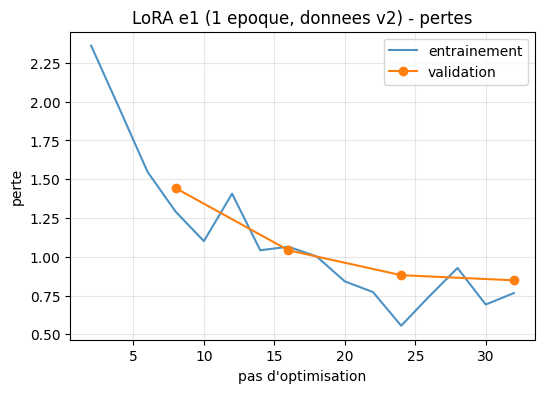

perte validation : premiere 1.4422 | derniere 0.8482
adaptateur e1 sauvegarde dans /kaggle/working/adaptateurs/e1

############################## BASE ##############################

> donne-moi une recette de ratatouille   [recommander] candidats=['Hollow Knight', 'Geometry Dash', 'Fall Guys']
Je suis désolé, mais je n'ai pas trouvé de jeu correspondant à votre demande de "recette de ratatouille". Cependant, je peux vous recommander quelques jeux de plateforme qui pourraient vous plaire :

- Hollow Knight (2017, 14.99$) : Un RPG metroidvania avec une structure de découverte et une pénalisation, idéal pour ceux qui aiment les jeux qui dem

> c'est quoi Hades exactement ?   [hors_sujet] candidats=[]
Hades est un jeu de rôle en temps réel développé par Pixelology Games. Il s'agit d'un jeu de stratégie et de gestion où le joueur devient le roi d'Hades, un monde fantastique avec des créatures légendaires. Le jeu offre une expérience immersive avec des combats stratégiques, des interactions

In [33]:
# ── courbe de e1, sauvegarde, premier apercu base / e4 / e1 ───────────────
import matplotlib.pyplot as plt

logs = entraineur_e1.state.log_history
pt = [(x["step"], x["loss"]) for x in logs if "loss" in x]
pv = [(x["step"], x["eval_loss"]) for x in logs if "eval_loss" in x]

plt.figure(figsize=(6, 4))
plt.plot(*zip(*pt), label="entrainement", alpha=.8)
plt.plot(*zip(*pv), marker="o", label="validation")
plt.xlabel("pas d'optimisation"); plt.ylabel("perte"); plt.legend(); plt.grid(alpha=.3)
plt.title("LoRA e1 (1 epoque, donnees v2) - pertes"); plt.show()
print("perte validation : premiere", round(pv[0][1], 4), "| derniere", round(pv[-1][1], 4))

# l'adaptateur disparait avec la session : il faut le telecharger tout de suite
modele_lora.save_pretrained('/kaggle/working/adaptateurs', selected_adapters=["e1"])
print("adaptateur e1 sauvegarde dans /kaggle/working/adaptateurs/e1\n")

APERCU = ["donne-moi une recette de ratatouille",
          "c'est quoi Hades exactement ?",
          "Hollow Knight ou Dead Cells pour quelqu'un qui debute ?"]
for nom, adaptateur, actif in [("BASE", "e1", False), ("ADAPTE e4", "default", True), ("ADAPTE e1", "e1", True)]:
    modele_lora.set_adapter(adaptateur)
    print("#" * 30, nom, "#" * 30)
    for msg in APERCU:
        rep, _, tr = pipeline.tour(modele_lora, tok, df, msg, temperature=0.3, adaptateur=actif)
        print(f"\n> {msg}   [{tr['intention']}] candidats={tr['candidats'][:3]}")
        print(rep[:350])
    print()
modele_lora.set_adapter("e1")

## Partie 8 — Évaluation comparative

Même récupération des deux côtés : la seule différence entre les exécutions est l'adaptateur.
Sans ça, la comparaison ne conclut rien.

Trois conditions, pour attribuer l'amélioration à la bonne cause.

In [34]:
# ── condition 1 : recuperation seule, sans modele -> ce que le filtre fait a lui seul
from schemas import analyse_vide

sans_modele = []
for attendue, message in REQUETES_TEST:
    a = analyse_vide()
    cands, _, _ = agent.recuperer(a, df, n=2)
    sans_modele.append({"message": message, "titres": [c["titre"] for c in cands]})
for r in sans_modele[:5]:
    print(f"{r['message'][:46]:<48} -> {', '.join(r['titres'])}")

j'ai adore Outer Wilds mais je saurais pas dir   -> Counter-Strike 2, Dota 2
je tourne en rond, plus rien ne me donne envie   -> Counter-Strike 2, Dota 2
j'ai aime Disco Elysium, qu'est-ce que ca dit    -> Counter-Strike 2, Dota 2
je sais pas ce que je cherche, propose-moi que   -> Counter-Strike 2, Dota 2
un jeu calme a jouer 45 minutes le soir apres    -> Counter-Strike 2, Dota 2
[base] j'ai adore Outer Wilds mais je saurais pas d   -> explorer_gout
[base] je tourne en rond, plus rien ne me donne env   -> explorer_gout
[base] j'ai aime Disco Elysium, qu'est-ce que ca di   -> explorer_gout
[base] je sais pas ce que je cherche, propose-moi q   -> explorer_gout
[base] un jeu calme a jouer 45 minutes le soir apre   -> recommander
[base] quelque chose de nerveux et exigeant mais pa   -> recommander
[base] un jeu cooperatif en ecran partage sur Mac a   -> recommander
[base] un jeu d'exploration sans combat, sur Linux    -> recommander
[base] je veux un truc relaxant mais qui me tienne    -

In [35]:
# ── conditions 2 a 4 : base, e4, e1 sur les memes requetes ────────────────
CONDITIONS = [("base", "e1", False), ("e4", "default", True), ("e1", "e1", True)]

def rejouer(adaptateur, actif, etiquette):
    modele_lora.set_adapter(adaptateur)
    torch.manual_seed(GRAINE)
    out = []
    for attendue, message in REQUETES_TEST:
        rep, _, tr = pipeline.tour(modele_lora, tok, df, message, systeme=prompts.SYSTEME_CONSEIL_B,
                                   temperature=0.3, adaptateur=actif)
        out.append({"message": message, "intention_attendue": attendue,
                    "intention_detectee": tr["intention"], "json_valide": tr["json_valide"],
                    "candidats": tr["candidats"], "titres_cites": tr["titres_cites"], "reponse": rep})
        print(f"[{etiquette:<4}] {message[:44]:<46} -> {tr['intention']}")
    return out

resultats = {nom: rejouer(adaptateur, actif, nom) for nom, adaptateur, actif in CONDITIONS}
modele_lora.set_adapter("e1")

for nom, r in resultats.items():
    with open(f"/kaggle/working/resultats_{nom}.json", "w", encoding="utf-8") as f:
        json.dump(r, f, ensure_ascii=False, indent=2)

[base] j'ai adore Outer Wilds mais je saurais pas d   -> explorer_gout
[base] je tourne en rond, plus rien ne me donne env   -> explorer_gout
[base] j'ai aime Disco Elysium, qu'est-ce que ca di   -> explorer_gout
[base] je sais pas ce que je cherche, propose-moi q   -> explorer_gout
[base] un jeu calme a jouer 45 minutes le soir apre   -> recommander
[base] quelque chose de nerveux et exigeant mais pa   -> recommander
[base] un jeu cooperatif en ecran partage sur Mac a   -> recommander
[base] un jeu d'exploration sans combat, sur Linux    -> recommander
[base] je veux un truc relaxant mais qui me tienne    -> recommander
[base] un jeu narratif court, moins de 10 euros       -> recommander
[base] quelque chose comme Stardew Valley mais en p   -> recommander
[base] c'est quoi Hades exactement ?                  -> hors_sujet
[base] Celeste est difficile au point de decourager   -> question_jeu
[base] Hollow Knight ou Dead Cells pour quelqu'un q   -> comparer
[base] Terraria ou Minecraft 

In [36]:
# ── metriques automatiques : l'analyse est commune, seules les reponses different
def hors_candidats(r):
    # titre du catalogue cite alors qu'il n'est ni candidat ni nomme par le joueur : invente
    detectes = [t for t in TITRES_LONGS if cite(t, r["reponse"])]
    # "Valley" dans "Stardew Valley" n'est pas une citation : on ne garde que les titres les plus longs
    detectes = [t for t in detectes if not any(t != d and t in d for d in detectes)]
    return [t for t in detectes if t not in r["candidats"] and not cite(t, r["message"])]

def metriques(res):
    n = len(res)
    flous = [r for r in res if r["intention_attendue"] == "explorer_gout"]
    hs    = [r for r in res if r["intention_attendue"] == "hors_sujet"]
    reco  = [r for r in res if r["intention_attendue"] in ("recommander", "affiner")]
    return {
        "reponses citant un titre non fourni": f"{sum(bool(hors_candidats(r)) for r in res)}/{n}",
        "gout flou : question sans recommandation": f"{sum('?' in r['reponse'] and not r['titres_cites'] for r in flous)}/{len(flous)}",
        "hors sujet : aucun jeu cite, retour aux jeux": f"{sum(not r['titres_cites'] and not hors_candidats(r) and 'jeu' in r['reponse'].lower() for r in hs)}/{len(hs)}",
        "recommandation : au moins un candidat cite": f"{sum(bool(r['titres_cites']) for r in reco)}/{len(reco)}",
        "intention bien routee (commune)": f"{sum(r['intention_detectee'] == r['intention_attendue'] for r in res)}/{n}",
        "JSON valide (commun)": f"{sum(r['json_valide'] for r in res)}/{n}",
        "longueur moyenne (mots)": round(sum(len(r["reponse"].split()) for r in res) / n),
    }

comparaison = pd.DataFrame({nom: metriques(r) for nom, r in resultats.items()})
print(comparaison.to_string())
comparaison.to_csv('/kaggle/working/metriques.csv')

                                               base     e4     e1
reponses citant un titre non fourni            5/20   5/20   2/20
gout flou : question sans recommandation        0/4    1/4    0/4
hors sujet : aucun jeu cite, retour aux jeux    1/4    1/4    2/4
recommandation : au moins un candidat cite      8/8    8/8    8/8
intention bien routee (commune)               17/20  17/20  17/20
JSON valide (commun)                          19/20  19/20  19/20
longueur moyenne (mots)                          81     40     36


In [37]:
# ── le modele choisit-il vraiment, ou recopie-t-il le top du score python ?
def accord(res):
    acc = []
    for r in res:
        top2  = set(t.lower() for t in r["candidats"][:2])
        cites = set(t.lower() for t in r["titres_cites"])
        if cites:
            acc.append(len(top2 & cites) / len(cites))
    return sum(acc) / len(acc) if acc else 0.0

for nom, res in resultats.items():
    print(f"accord avec le top-2 python, {nom:<4} : {accord(res):.0%}")
print("\n100 % = le modele ne decide rien. 40-60 % avec de bonnes justifications = il arbitre.")

accord avec le top-2 python, base : 53%
accord avec le top-2 python, e4   : 67%
accord avec le top-2 python, e1   : 41%

100 % = le modele ne decide rien. 40-60 % avec de bonnes justifications = il arbitre.


In [38]:
# ── les 20 requetes cote a cote : on y choisit les 5 cas a commenter ───────
for i, (attendue, message) in enumerate(REQUETES_TEST):
    print("=" * 76)
    print(f"[{i}] ({attendue}) {message}")
    for nom, res in resultats.items():
        r = res[i]
        inventes = hors_candidats(r)
        alerte = f"  [titre invente : {', '.join(inventes)}]" if inventes else ""
        print(f"\n  {nom.upper():<4}{alerte} : {r['reponse'][:260]}")
    print()

[0] (explorer_gout) j'ai adore Outer Wilds mais je saurais pas dire pourquoi

  BASE : Outer Wilds est un jeu de survie et d'aventure qui offre une expérience immersive et intense. Il met en scène une exploration de planètes désertiques, où vous devez survivre à travers des situations extrêmes tout en résolvant des puzzles et des défis. La riche

  E4   : Je vais eviter de deviner, c'est pour toi de me le faire. Une question avant de me lancer. Outer Wilds t'a plu parceque elle aborde ca autrement que les autres jeux de ce genre ?

  E1   : Outer Wilds partage avec Sally Face - Episode One son cote narratif. Autre piste : si le cote narratif de Outer Wilds t'a plu, Maize le retrouve.

[1] (explorer_gout) je tourne en rond, plus rien ne me donne envie de jouer

  BASE : Désolé, je ne peux pas vous aider avec ça.

  E4   : Dota 2 (2013, 0.00$) partage avec Counter-Strike 2 le fait d'etre un FPS, mais sur une duree plus courte. Et Terraria (2011, 9.99$) reprend ce qui faisait la force de 

**Résultats : tableau comparatif (20 requêtes de test, température 0.3)**

| Métrique | base | e4 | e1 |
|---|---|---|---|
| Réponses citant un titre non fourni (alertes automatiques) | 5/20 | 5/20 | 2/20 |
| … dont inventions réelles après vérification manuelle | 1/20 | 1/20 | 0/20 |
| Goût flou : question sans recommandation | 0/4 | 1/4 | 0/4 |
| Hors sujet : aucun jeu cité, retour aux jeux | 1/4 | 1/4 | 2/4 |
| Recommandation : au moins un candidat cité | 8/8 | 8/8 | 8/8 |
| Longueur moyenne (mots) | 81 | 40 | 36 |
| Accord avec le top-2 du score Python | 53 % | 67 % | 41 % |
| Intention bien routée (analyse commune) | 17/20 | 17/20 | 17/20 |
| JSON valide (analyse commune) | 19/20 | 19/20 | 19/20 |

Vérification des alertes « titre non fourni » : sur les 12 alertes, 10 sont des faux positifs
(titre contenu dans un titre plus long et légitimement cité : « Together » dans Don't Starve
Together, « Valley » dans Stardew Valley, « Dungeons » dans Minecraft Dungeons, « Hollow » dans
Hollow Knight, « Euro Truck Simulator » dans Euro Truck Simulator 2). Restent : Starbound
(base, requête 12) et The Elder Scrolls Online (e4, requête 16). Les titres absents du catalogue,
comme Zelda Breath of the Wild cité par e4, échappent à ce contrôle.

Analyse JSON seule : 17/20 sur le test, 8/10 en validation. Le score de test est passé de 19/20
à 17/20 après l'ajout de la gestion des rejets dans le prompt d'analyse ; le score de validation,
seul indicateur honnête puisque jamais utilisé pour la mise au point, est inchangé.

Lecture :
- Hors sujet : e1 redirige vers les jeux dans 2 cas sur 4, la base dans 1 sur 4 — la base va
  jusqu'à détailler la procédure de changement de mot de passe Steam.
- Concision : e1 répond en 36 mots en moyenne contre 81 pour la base, conformément à la
  consigne « 6 phrases maximum » que le prompt seul ne fait pas respecter.
- Fidélité au catalogue : aucune invention de titre vérifiée pour e1, une pour la base et e4.
- Choix des jeux : e1 s'écarte le plus du top-2 Python (41 %), e4 le recopie le plus (67 %).
- Échec commun : aucune condition ne pose la question attendue sur un goût flou, sauf e4 une
  fois ; e1 a régressé sur ce point (cas 3).

**Grille humaine — notée 0 à 2 par les quatre membres, indépendamment**

Proposition de départ établie sur les 20 réponses de chaque condition, à confronter aux notes
des quatre membres :

| Critère | 0 | 1 | 2 | base | e4 | e1 |
|---|---|---|---|---|---|---|
| Pertinence | hors sujet | approximative | adaptée | 1 | 0 | 1 |
| Respect du rôle | rôle perdu | partiel | tenu | 1 | 1 | 2 |
| Prise en compte de l'historique | ignoré | partiel | exploité | — | — | — |
| Reconnaissance du hors-périmètre | répond quand même | hésite | redirige nettement | 0 | 0 | 1 |
| Informations inventées | plusieurs | une | aucune | 0 | 0 | 1 |
| Pertinence de la question | inutile | générique | sépare deux lectures du goût | 0 | 1 | 0 |
| Reformulation du goût | absente | répète la demande | nomme ce qui relie les jeux | 1 | 0 | 0 |
| Justification non interchangeable | générique | partielle | propre à ce joueur | 1 | 0 | 1 |
| Réserve signalée | tait un défaut | vague | dit ce qui cloche | 0 | 0 | 0 |
| Total (sur 16) | | | | 4 | 2 | 6 |

L'historique n'est pas évaluable sur ce jeu de test, qui ne contient que des requêtes d'un seul
tour ; il se juge dans l'interface, sur un dialogue à plusieurs tours. Pour e1, « informations
inventées » vaut 1 et non 2 : aucun titre inventé, mais des traits faux attribués aux jeux
(Crusader Kings III « nerveux », Grim Dawn « calme »).

**Cinq cas commentés**

1. Hors sujet, « comment je change le mot de passe de mon compte Steam ? » (requête 17).
   La base donne la procédure étape par étape : rôle perdu. e4 propose des « jeux basiques »
   sans rapport. e1 refuse et ramène vers son rôle (« ce que je sais faire, c'est donner des
   pistes pour trouver un jeu »). C'est le comportement appris par la famille hors_sujet des
   données v2, que ni le prompt A ni le prompt B n'obtenaient du modèle de base.

2. « Calcule la dérivée de x^3 sin(x) » (requête 19).
   L'analyse s'est trompée et a classé la demande en recommandation, si bien que des jeux
   candidats ont été fournis au modèle. e4 enchaîne alors sur Hollow Knight et Dead Cells. e1,
   lui, refuse quand même et propose de revenir aux jeux : l'adaptation rattrape ici une erreur
   de l'étape d'analyse.

3. Goût flou, « j'ai adoré Outer Wilds mais je saurais pas dire pourquoi » (requête 0).
   L'analyse a correctement détecté explorer_gout. La base décrit Outer Wilds en inventant
   (« planètes désertiques », « survie »). e4 pose une question, maladroite mais conforme. e1
   recommande directement Sally Face et Maize. Régression : dans les données v2, la question ne
   représente que 110 réponses sur 623 ; en une seule époque, e1 a surtout retenu le schéma
   dominant « deux jeux et un trait partagé », sans le conditionner au champ « Clarification
   nécessaire » du contexte.

4. « Un jeu calme à jouer 45 minutes le soir » (requête 4).
   Les trois conditions s'appuient sur Dark Souls III, et e1 affirme que Grim Dawn « garde le
   côté calme de Dark Souls III ». Deux causes : la récupération favorise les jeux très
   populaires sans relier « calme » à des candidats pertinents ; puis e1 a appris un raccourci —
   dans ses données, le trait cité était toujours le trait demandé, il le recopie donc sans
   vérifier la fiche.

5. « C'est quoi Hades exactement ? » (requête 11).
   L'analyse n'a pas rangé Hades parmi les jeux cités, et la règle Python a requalifié la demande
   en hors sujet : aucune fiche n'est fournie. Sans fait du catalogue, les réponses inventent ou
   restent vides : un studio « Atrius Games » pour la base, Zelda Breath of the Wild pour e4,
   un « côté classique » sans contenu pour e1. C'est la démonstration directe du principe du
   projet : quand le catalogue ne fournit pas le fait, le modèle l'invente ou n'a rien à dire.

**Limites**

Le modèle de base ne suit pas les consignes de comportement : il ne pose pas de question, ne
redirige pas le hors-sujet et dépasse la longueur demandée. L'adaptation améliore la
redirection, la concision et la fidélité aux titres du catalogue, mais pas la question de
clarification ni l'exactitude des traits cités, à cause d'un déséquilibre et d'un raccourci dans
les données générées. Côté Python, la recherche tolérante associe « Minecraft » à Minecraft
Dungeons, un autre jeu. Une seule configuration a été entraînée par adaptateur : la variance
entre essais n'est pas mesurée.

## Partie 9 — Interface

In [39]:
# ── Gradio : bascule base / e4 / e1 pour montrer la comparaison en direct ──
import gradio as gr, inspect, threading
from schemas import etat_vide

print("gradio", gr.__version__)

# une interface deja lancee garde son port : on la ferme avant d'en relancer une
if "demo" in globals():
    try:
        demo.close()
    except Exception:
        pass                                   # deja fermee par le bouton : rien a faire

# "type" n'existe plus dans les versions ou messages est le seul format
_kw = {"type": "messages"} if "type" in inspect.signature(gr.Chatbot.__init__).parameters else {}

# libelle -> (adaptateur a activer, adaptateur utilise pour rediger)
MODELES = {"base (sans LoRA)":                ("e1", False),
           "LoRA e4 (4 epoques, donnees v1)": ("default", True),
           "LoRA e1 (1 epoque, donnees v2)":  ("e1", True)}


def _ajouter(fil, message, reponse):
    # les versions recentes de Gradio n'acceptent que ce format
    return (fil or []) + [{"role": "user", "content": message},
                          {"role": "assistant", "content": reponse}]


def repondre_ui(message, fil, etat, choix, temperature):
    if not message.strip():
        return fil, etat, "", ""
    adaptateur, actif = MODELES[choix]
    modele_lora.set_adapter(adaptateur)
    texte, etat, tr = pipeline.tour(modele_lora, tok, df, message, etat=etat,
                                    systeme=prompts.SYSTEME_CONSEIL_B,
                                    temperature=temperature, adaptateur=actif)
    diag = (f"intention    : {tr['intention']} (modele : {tr['intention_modele']})\n"
            f"JSON valide  : {tr['json_valide']}\n"
            f"candidats    : {', '.join(tr['candidats'][:6])}\n"
            f"titres cites : {', '.join(tr['titres_cites']) or 'aucun'}\n"
            f"contraintes  : plateformes={etat['plateformes']} prix_max={etat['prix_max']}")
    return _ajouter(fil, message, texte), etat, "", diag


def arreter_ui():
    # fermer le serveur pendant sa propre requete couperait la reponse : on attend une seconde
    threading.Timer(1.0, demo.close).start()
    return "**Interface arretee.**"


with gr.Blocks(title="Conseiller de jeux Steam") as demo:
    gr.Markdown("## Conseiller de jeux Steam\n"
                "Raconte-moi ce que tu as aime, meme vaguement : je creuse avant de proposer.\n\n"
                "*Je ne recommande que des jeux du catalogue. Pas de support Steam, "
                "et je ne garantis pas les prix (catalogue arrete en mars 2025). "
                "Apres un changement de modele, clique sur Recommencer.*")
    with gr.Row():
        choix = gr.Radio(list(MODELES), value="LoRA e1 (1 epoque, donnees v2)", label="Modele")
        temp  = gr.Slider(0.1, 1.2, value=0.4, step=0.1, label="Temperature")

    chat  = gr.Chatbot(height=420, **_kw)
    etat  = gr.State(etat_vide())
    champ = gr.Textbox(placeholder="Ecris ton message...", show_label=False)
    with gr.Row():
        envoyer = gr.Button("Envoyer", variant="primary")
        reset   = gr.Button("Recommencer")
        arreter = gr.Button("Arreter l'interface", variant="stop")
    statut = gr.Markdown()
    with gr.Accordion("Ce que l'agent a compris", open=False):
        diagnostic = gr.Textbox(lines=5, show_label=False)

    entrees, sorties = [champ, chat, etat, choix, temp], [chat, etat, champ, diagnostic]
    champ.submit(repondre_ui, entrees, sorties)
    envoyer.click(repondre_ui, entrees, sorties)
    reset.click(lambda: ([], etat_vide(), "", ""), None, sorties)   # vide aussi l'etat
    arreter.click(arreter_ui, None, statut)

demo.launch(share=True, prevent_thread_lock=True)   # sans ca, la sauvegarde Kaggle ne termine jamais

gradio 6.26.0
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://070d7ec47929fc4f53.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
